<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQML_IntrusionPhishingURL_Gunasridharan2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QML + BB84 framework for intrusion, phishing and malicious-URL detection: Gunasridharan et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Ramasubramaniyan Gunasridharan, Ali Altalbe, Bharathi Mohan Gurusamy, Gundala Pallavi and Prasanna Kumar Rangarajan,
> "A Hybrid Framework Integrating QML, AI, and Quantum-Safe Cryptography for Cybersecurity",
> *Journal of Computational and Cognitive Engineering* 5(1), 16-29 (2026; online September 2025).
> https://doi.org/10.47852/bonviewjcce52025121

The paper proposes a "hybrid" security framework with two quantum parts. (1) Five quantum-machine-learning (QML) detectors,
a variational quantum classifier (**VQC**), a quantum support-vector classifier (**QSVC**), a quantum neural network (**QNN**),
a Pegasos-trained QSVC and a quantum convolutional neural network (**QCNN**), are applied to four detection tasks:
network-intrusion flows (HIKARI), phishing from network/URL parameters, phishing from e-mail content, and malicious URLs.
Table 2 of the paper lists a "score before optimisation" and "score after optimisation" for every model and task.
(2) The **BB84** quantum-key-distribution protocol is simulated with and without an eavesdropper (Qiskit and Cirq).
Post-quantum cryptography (Kyber, Dilithium and similar) is only named in the paper; no experiment or number is given for it.

**What the notebook does.** It downloads real public data (HIKARI-2021 from Zenodo, the UCI Phishing Websites data, a Hugging Face
e-mail corpus and a Hugging Face malicious-URL corpus), rebuilds the engineered features the paper describes (entropy scores, keyword
counts, URL structure), shows the data, trains the classical models of the paper's Figures 8-11, trains the five QML models in a
"before" and an "after" configuration on a CPU simulator, simulates BB84 (no eavesdropper, intercept-resend eavesdropper, noisy channel),
and prints every checkable number of the paper next to ours with a verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, *Runtime -> Run all*. The first cell installs pinned
versions; if Colab asks you to restart the session, restart and run all again. No GPU, no IBM account and no Hugging Face token
are needed (all four data sets are public).

**Runtime.** `FAST_MODE = True`: about 13 minutes on a shared laptop CPU (one seed, 50 training rows per task, 40 optimiser iterations). `FAST_MODE = False` (the version stored here): the budgets in the
configuration cell (two seeds, 80 training and 200 test rows, 80 optimiser iterations); it took 86 minutes on a laptop CPU that other jobs were using at the same time, so allow 1 to 1.5 hours. Colab's CPU runtime is similar.

**What you get at the end.** Four data-exploration figures, the drawn quantum circuits, a BB84 table, Table 2 of the paper rebuilt
with our numbers, a table of verdicts, and a critical reading of the paper.

## The paper in one page

**Problem.** Quantum computers threaten RSA/ECC, while AI-based security tools can themselves be attacked. The authors combine
(a) quantum-machine-learning detectors for classical cyber-threats with (b) quantum-safe key exchange (BB84) so that the
detector's traffic and keys are protected.

**Data (Sect. 3.1, 4).** Three named data sets: *HIKARI Flow* (intrusion detection: encrypted synthetic attack traffic mixed with benign flows),
a *Phishing* data set used in two forms (network parameters; e-mail content) and a *Malicious URL* data set. Section 4.2 says "four" data sets but lists three;
Table 2 has four rows (HIKARI, phishing e-mail, phishing network parameters, malicious URL). The authors say the data are "available from the corresponding author
upon reasonable request"; no file, size, split or version is given.

**Features (Sect. 3.1.1).** HIKARI: entropy scores of packet randomness, flow duration, protocol type, port usage. Phishing: urgent/password keywords,
header inconsistencies, URL length, domain age. URL: URL entropy, subdomain complexity, domain registration period. All numeric features are standardised into [0, 1].

**Models (Sect. 3.3-3.4).** VQC (feature map + ansatz, classical optimiser), QSVC with a fidelity quantum kernel, QNN, QSVC trained with
Pegasos (stochastic sub-gradient descent, regularisation C and tau steps) and QCNN. "Optimisation" means noise mitigation (calibration matrix, randomised circuit
averaging), custom quantum kernels, hyper-parameter tuning, Adam (QNN, VQC) and COBYLA (QSVC), and a layer/ansatz search. Classical comparison models:
random forest, gradient boosting, extra trees, decision tree, naive Bayes, XGBoost, CatBoost and neural networks (Figures 8-11, bar charts without printed values).

**Claims.** (i) VQC reaches 95.12 % accuracy on traffic patterns; (ii) QSVC reaches 97.75 % accuracy for phishing detection (98.75 % on e-mail content);
(iii) QNN reaches a 95.62 % F1 score on malicious URLs; (iv) Table 2 scores rise from 0.53-0.79 before to 0.89-0.99 after optimisation;
(v) QML models beat random forest, gradient boosting and neural networks on every task; (vi) noise mitigation improves accuracy by 20 %;
(vii) BB84 gives a 100 % key match without an eavesdropper and a detectable error rate with one (Figures 4-6), simulated in Qiskit and Cirq;
(viii) post-quantum cryptography is integrated (no experiment).

## What follows the paper and what had to be chosen

The paper publishes no code, no data files, no qubit count, no circuit, no split and no definition of the "score" in Table 2. Everything that is missing is
chosen here and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| HIKARI data | "HIKARI Flow", private copy | HIKARI-2021 flow table `ALLFLOWMETER_HIKARI2021.csv` (Zenodo 6463389, public), class-balanced sample of about 1,500 flows per traffic category |
| Phishing, network parameters | Not named | UCI "Phishing Websites" (id 327, 11,055 rows, 30 URL/network parameters) as the closest public data set |
| Phishing, e-mail content | Not named | Hugging Face `zefang-liu/phishing-email-dataset` (18,650 e-mails; balanced sample of 5,000) with the keyword/entropy features the paper lists |
| Malicious URL | Not named | Hugging Face `JorgeGMM/malicious_urls` (16,000 URLs, benign / malicious) with URL-entropy, subdomain and length features; the domain registration period needs WHOIS look-ups and is not available |
| Entropy of HIKARI flows | Entropy of "packet randomness" | The flow table has no payload bytes, so two flow-level entropies are used: entropy of the forward/backward payload split and entropy of the TCP-flag counts |
| Scaling | [0, 1] standardisation | Fitted on the training split only: log1p of heavy-tailed counts, `SelectKBest(f_classif)`, `StandardScaler`, `PCA(n_components = N_QUBITS)`, `MinMaxScaler((0, pi))`; test angles clipped to [0, pi] |
| Number of qubits | Not stated (Figure 6 shows a 10-qubit BB84 circuit only) | 4 qubits, one PCA component per qubit (4 is also what a QCNN needs: 4 -> 2 -> 1) |
| "Score" in Table 2 | Not defined | Test-set accuracy (F1 is reported next to it) |
| "Before optimisation" | Not defined | Library defaults without tuning: `z_feature_map` (1 repetition), `real_amplitudes` (1 repetition), 10 optimiser iterations, QSVC with C = 1 and no kernel bandwidth, Pegasos with 10 steps |
| "After optimisation" | Noise mitigation, custom kernels, tuning, Adam/COBYLA | `zz_feature_map` (entangling), deeper ansatz, a larger iteration budget, kernel bandwidth and C tuned by 5-fold cross-validation on the training rows; **no** noise mitigation (simulation is noiseless) |
| Optimiser | Adam for QNN/VQC, COBYLA for QSVC | COBYLA for all variational models: Adam needs parameter-shift gradients and was about 30 times slower per optimiser iteration on a CPU simulator (a measured 27 s against 0.9 s) |
| QSVC and Pegasos regularisation | C and tau tuned | QSVC: C and bandwidth tuned by 5-fold cross-validation on the training rows; Pegasos: C = 1000 (Qiskit default), tau = 100 steps (10 before) |
| Classical models | RF, GB, ET, DT, NB, XGB, CatBoost, NN | DT, NB, RF, GB, ET, XGBoost, MLP, SVC-RBF (CatBoost is not installed in Colab by default and is left out) |
| Split | Not stated | Stratified; quantum models see a small class-balanced sample (the paper's cost is not stated), classical models a 70/30 split of the pool |
| Seeds | Not stated | `SEED = 42`; the full run adds seed 43 |
| BB84 | Qiskit + Cirq, 100 % key match, eavesdropper detected | Qiskit + Aer, dynamic circuit for the intercept-resend eavesdropper, QBER threshold 11 %; Cirq is not installed in Colab and is not run |
| Post-quantum cryptography | Mentioned | Not evaluated: the paper reports no PQC experiment or timing |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and xgboost.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc ucimlrepo huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 13 minutes. False: the larger budgets below (86 minutes measured on a loaded laptop CPU).

SEED     = 42
DATA_DIR = "qc133_data"    # downloads are cached here (a scratch folder, never committed)
IBM_TOKEN = ""             # optional; the paper's simulations need no real hardware, so this notebook never uses it
HF_TOKEN_NOTE = "all four data sets are public; a Hugging Face token is only used if present"

# Data sizes
HIKARI_PER_CATEGORY = 1500   # flows kept per HIKARI traffic category (real counts are printed in Section 1)
EMAIL_PER_CLASS     = 2500   # e-mails kept per class
CLASSICAL_TRAIN_CAP = 3000   # rows used to train the classical comparison models (Section 3)
VIS_TRAIN           = 600    # points drawn in the Section 2 scatter plots

# Quantum models
N_QUBITS = 4                 # CHOICE: one PCA component per qubit; a 4-qubit QCNN halves to 2 and then 1 qubit
K_SELECT = 10                # SelectKBest keeps this many engineered features before PCA
if FAST_MODE:
    N_TRAIN_Q, N_TEST_Q = 50, 100         # class-balanced sample of the quantum models
    BEFORE_ITERS, AFTER_ITERS = 10, 40    # optimiser iterations ("before" / "after"), COBYLA
    PEG_STEPS_BEFORE, PEG_STEPS_AFTER = 10, 100
    SEEDS = [SEED]
    BW_GRID, C_GRID = [0.25, 0.5, 1.0, 2.0], [1, 10, 100]
else:
    N_TRAIN_Q, N_TEST_Q = 80, 200
    BEFORE_ITERS, AFTER_ITERS = 10, 80
    PEG_STEPS_BEFORE, PEG_STEPS_AFTER = 10, 100
    SEEDS = [SEED, SEED + 1]
    BW_GRID, C_GRID = [0.25, 0.5, 1.0, 1.5, 2.0], [1, 10, 100]

# BB84 (Section 5)
BB84_BITS_PER_CIRCUIT = 10   # the paper's Figure 6 shows a 10-qubit circuit
BB84_CIRCUITS = 100 if FAST_MODE else 400
QBER_THRESHOLD = 0.11        # usual BB84 abort threshold (the paper's Eq. 4 threshold is not given)
print(f"FAST_MODE={FAST_MODE}  qubits={N_QUBITS}  train/test={N_TRAIN_Q}/{N_TEST_Q}  iterations before/after={BEFORE_ITERS}/{AFTER_ITERS}  seeds={SEEDS}")

FAST_MODE=False  qubits=4  train/test=80/200  iterations before/after=10/80  seeds=[42, 43]


In [3]:
import os, re, io, time, math, zipfile, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import z_feature_map, zz_feature_map, real_amplitudes, efficient_su2
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_machine_learning.algorithms import VQC, QSVC, PegasosQSVC, NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Hugging Face token (optional; the data sets used here are public). Resolved only from the environment or Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data and the paper's engineered features

The paper's data are private, so each of its four tasks is rebuilt from the closest public data set of the same kind (see the table above).
All four are downloaded here and cached in `DATA_DIR`. Nothing is simulated or invented: every row below is a real observation with its real label.

* **HIKARI-2021** (Ferriyan et al., 2021): flow records (Zeek/`flowmeter` features) of real encrypted traffic, benign and attack. The
  original table has six traffic categories (`Benign`, `Background`, `Probing`, `Bruteforce`, `Bruteforce-XML`, `XMRIGCC CryptoMiner`) and a binary `Label`
  (0 = Benign or Background, 1 = attack). The CSV is 302 MB (68 MB zipped); the notebook streams it once, keeps about 1,500 flows per category and deletes the download.
* **UCI Phishing Websites** (Mohammad et al.): 30 URL / page / domain parameters per site (values -1, 0, 1); `Result` = -1 phishing, 1 legitimate.
* **Phishing e-mails**: 18,650 e-mails labelled `Phishing Email` or `Safe Email`; a balanced sample is used.
* **Malicious URLs**: 16,000 URLs labelled `benign` or `malicious`.

The positive class is always the attack: *attack flow*, *phishing*, *phishing e-mail*, *malicious URL*.

In [4]:
def shannon(counts):
    # Shannon entropy (bits) of the last axis of a count array
    c = np.asarray(counts, float); s = c.sum(axis=-1, keepdims=True)
    p = np.where(s > 0, c / np.where(s == 0, 1, s), 0.0)
    return -np.where(p > 0, p * np.log2(np.where(p > 0, p, 1.0)), 0.0).sum(axis=-1)

def text_entropy(s):
    if not s: return 0.0
    _, c = np.unique(list(s), return_counts=True); return float(shannon(c))

def download(urls, path):
    last = None
    for u in urls:
        try:
            with requests.get(u, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(path, "wb") as f:
                    for ch in r.iter_content(1 << 20): f.write(ch)
            return path
        except Exception as e:
            last = e; print("download failed:", u[:70], type(e).__name__)
    raise RuntimeError(f"could not download {path}: {last}")

# ---------------- HIKARI-2021 ----------------
HIKARI_URLS = ["https://zenodo.org/api/records/6463389/files/ALLFLOWMETER_HIKARI2021.csv.zip/content",
               "https://zenodo.org/records/6463389/files/ALLFLOWMETER_HIKARI2021.csv.zip?download=1"]
def load_hikari(per_cat=HIKARI_PER_CATEGORY, seed=SEED):
    cache = os.path.join(DATA_DIR, f"hikari_sample_{per_cat}.csv.gz"); meta = os.path.join(DATA_DIR, "hikari_counts.json")
    if os.path.exists(cache) and os.path.exists(meta):
        return pd.read_csv(cache), json.load(open(meta))
    z = download(HIKARI_URLS, os.path.join(DATA_DIR, "hikari.zip"))
    zf = zipfile.ZipFile(z); name = zf.namelist()[0]
    with zf.open(name) as f: counts = pd.read_csv(f, usecols=["traffic_category"])["traffic_category"].value_counts()
    frac = (per_cat / counts).clip(upper=1.0); g = np.random.default_rng(seed); keep = []
    with zf.open(name) as f:
        for ch in pd.read_csv(f, chunksize=200_000):                    # large CSV: read in chunks
            keep.append(ch[g.random(len(ch)) < ch["traffic_category"].map(frac).to_numpy()])
    df = pd.concat(keep, ignore_index=True); zf.close(); os.remove(z)   # delete the 68 MB download
    df.to_csv(cache, index=False, compression="gzip"); json.dump({k: int(v) for k, v in counts.items()}, open(meta, "w"))
    return df, json.load(open(meta))

def hikari_features(df):
    f = pd.DataFrame(index=df.index)
    f["flow_duration"] = df["flow_duration"]; f["pkts_total"] = df["fwd_pkts_tot"] + df["bwd_pkts_tot"]
    f["bytes_total"] = df["flow_pkts_payload.tot"]; f["pkts_per_sec"] = df["flow_pkts_per_sec"]
    f["payload_bytes_per_sec"] = df["payload_bytes_per_second"]; f["iat_mean"] = df["flow_iat.avg"]
    f["payload_mean"] = df["flow_pkts_payload.avg"]; f["payload_std"] = df["flow_pkts_payload.std"]; f["down_up_ratio"] = df["down_up_ratio"]
    # CHOICE: the paper's "entropy scores" need payload bytes, which a flow table does not contain; two flow-level entropies instead
    f["entropy_direction"] = shannon(df[["fwd_pkts_payload.tot", "bwd_pkts_payload.tot"]].to_numpy())
    f["entropy_flags"] = shannon(df[["flow_FIN_flag_count", "flow_SYN_flag_count", "flow_RST_flag_count", "fwd_PSH_flag_count", "flow_ACK_flag_count"]].to_numpy())
    f["port_https"] = (df["responp"] == 443).astype(float); f["port_http"] = (df["responp"] == 80).astype(float)   # port usage
    f["port_high"] = (df["responp"] >= 1024).astype(float); f["init_window_fwd"] = df["fwd_init_window_size"]
    return f.replace([np.inf, -np.inf], np.nan).fillna(0.0)

# ---------------- UCI Phishing Websites ----------------
def load_phish_net():
    cache = os.path.join(DATA_DIR, "uci_phishing_327.csv")
    if os.path.exists(cache): return pd.read_csv(cache)
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=327)
    df = ds.data.features.copy(); df["Result"] = ds.data.targets.iloc[:, 0].to_numpy()
    df.to_csv(cache, index=False); return df

# ---------------- phishing e-mails ----------------
def load_phish_email(n_per_class=EMAIL_PER_CLASS, seed=SEED):
    cache = os.path.join(DATA_DIR, f"phish_email_sample_{n_per_class}.csv.gz")
    if os.path.exists(cache): return pd.read_csv(cache)
    from huggingface_hub import hf_hub_download
    p = hf_hub_download("zefang-liu/phishing-email-dataset", "Phishing_Email.csv", repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf_email"), token=HF_TOKEN)
    raw = pd.read_csv(p).dropna(subset=["Email Text", "Email Type"]); raw = raw[raw["Email Text"].str.len() > 0]
    df = pd.concat([g.sample(min(n_per_class, len(g)), random_state=seed) for _, g in raw.groupby("Email Type")], ignore_index=True)[["Email Text", "Email Type"]]
    df.to_csv(cache, index=False, compression="gzip"); os.remove(p)       # delete the 52 MB source file
    return df

KW_URGENT = ["urgent", "immediately", "asap", "act now", "expire", "suspended", "verify", "confirm", "alert", "warning", "limited time", "final notice"]
KW_CRED   = ["password", "login", "log in", "account", "bank", "credit card", "ssn", "username", "update your", "click here", "paypal", "security"]
def email_features(df):
    t = df["Email Text"].astype(str); lo = t.str.lower(); f = pd.DataFrame(index=df.index)
    f["urgent_kw"] = sum(lo.str.count(re.escape(k)) for k in KW_URGENT)            # "urgent / password keywords" (Sect. 3.1.1)
    f["credential_kw"] = sum(lo.str.count(re.escape(k)) for k in KW_CRED)
    f["n_urls"] = lo.str.count(r"http|www\.")
    f["url_max_len"] = lo.apply(lambda s: max([len(u) for u in re.findall(r"(?:https?://|www\.)\S+", s)] or [0]))   # URL length
    f["text_len_log"] = np.log1p(t.str.len()); f["entropy"] = t.str[:2000].apply(text_entropy)
    f["exclam"] = t.str.count("!"); f["upper_ratio"] = t.apply(lambda s: sum(c.isupper() for c in s) / max(1, len(s)))
    f["digit_ratio"] = t.apply(lambda s: sum(c.isdigit() for c in s) / max(1, len(s))); f["html_tags"] = lo.str.count(r"<[a-z/][^>]*>")
    f["has_at_or_dollar"] = t.str.count(r"[@$]"); f["money_words"] = lo.str.count(r"\b(?:money|million|dollars?|cash|prize|winner|lottery|free)\b")
    return f.astype(float)       # CHOICE: header inconsistencies and domain age are not in the e-mail text file

# ---------------- malicious URLs ----------------
def load_urls():
    cache = os.path.join(DATA_DIR, "malicious_urls.csv")
    if os.path.exists(cache): return pd.read_csv(cache)
    from huggingface_hub import hf_hub_download
    p = hf_hub_download("JorgeGMM/malicious_urls", "train_malicious_url.jsonl", repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf_url"), token=HF_TOKEN)
    raw = pd.read_json(p, lines=True); df = pd.DataFrame({"url": raw["input"].astype(str), "label": raw["output"].astype(str)})
    df.to_csv(cache, index=False); return df

def url_features(urls):
    f = pd.DataFrame(index=urls.index)
    host = urls.str.replace(r"^[a-zA-Z]+://", "", regex=True).str.split("/").str[0].str.split("?").str[0]
    f["url_length"] = urls.str.len(); f["url_entropy"] = urls.apply(text_entropy); f["host_length"] = host.str.len()
    f["n_subdomains"] = host.str.count(r"\.").clip(lower=1) - 1                    # subdomain complexity
    f["n_dots"] = urls.str.count(r"\."); f["n_hyphen"] = urls.str.count("-"); f["n_digits"] = urls.str.count(r"\d")
    f["digit_ratio"] = f["n_digits"] / f["url_length"].clip(lower=1); f["n_special"] = urls.str.count(r"[^A-Za-z0-9./:\-]")
    f["path_depth"] = urls.str.replace(r"^[a-zA-Z]+://", "", regex=True).str.count("/")
    f["has_ip"] = host.str.match(r"^\d{1,3}(\.\d{1,3}){3}").astype(float); f["is_https"] = urls.str.startswith("https").astype(float)
    f["has_at"] = urls.str.contains("@").astype(float); f["n_query"] = urls.str.count(r"[?&=]"); f["tld_length"] = host.str.split(".").str[-1].str.len()
    return f.astype(float)       # CHOICE: the domain registration period would need WHOIS look-ups and is left out

In [5]:
t0 = time.perf_counter()
hik, HIK_COUNTS = load_hikari()
phn = load_phish_net()
pem = load_phish_email()
urls = load_urls()

DATA = {}
DATA["HIKARI Flow"] = dict(X=hikari_features(hik), y=hik["Label"].astype(int).to_numpy(), cat=hik["traffic_category"].to_numpy(), pos="attack flow", raw_rows=len(hik))
DATA["Phishing (email content)"] = dict(X=email_features(pem), y=(pem["Email Type"] == "Phishing Email").astype(int).to_numpy(), cat=pem["Email Type"].to_numpy(), pos="phishing e-mail", raw_rows=len(pem))
DATA["Phishing (network parameters)"] = dict(X=phn.drop(columns="Result").astype(float), y=(phn["Result"] == -1).astype(int).to_numpy(),
                                             cat=np.where(phn["Result"] == -1, "phishing site", "legitimate site"), pos="phishing site", raw_rows=len(phn))
DATA["Malicious URL"] = dict(X=url_features(urls["url"]), y=(urls["label"] == "malicious").astype(int).to_numpy(), cat=urls["label"].to_numpy(), pos="malicious URL", raw_rows=len(urls))
TASKS = list(DATA)
print(f"loaded in {time.perf_counter() - t0:.0f} s")
for k, d in DATA.items():
    print(f"{k:32s} X{d['X'].shape}  positives {d['y'].sum():5d} / {len(d['y'])}")

loaded in 34 s
HIKARI Flow                      X(9056, 15)  positives  5984 / 9056
Phishing (email content)         X(5000, 12)  positives  2500 / 5000
Phishing (network parameters)    X(11055, 30)  positives  4898 / 11055
Malicious URL                    X(16000, 15)  positives  7971 / 16000


## Dataset Exploration and Visualisation

For each data set: shape, feature names, the original label values with their counts, a bar chart of the real classes and a 2-D scatter in which **every point is a real
observation coloured by its ground-truth label**. The scatter is shown twice, as the quantum models see it: first the raw PCA coordinates (PCA fitted on the training split only),
then the same two coordinates scaled to the rotation-angle range [0, pi] (angle encoding). For HIKARI the colours are the six real traffic categories, not just attack versus benign.

The preprocessing function used by the models is defined first (every transform is fitted on the training split only).

In [6]:
HEAVY_MIN, HEAVY_MAX = 0.0, 100.0

def prepare(task, seed, n_train, n_test, n_qubits=None):
    # Class-balanced sample -> stratified train/test split -> log1p of heavy-tailed columns -> SelectKBest -> StandardScaler -> PCA -> MinMax(0, pi).
    # Everything is fitted on the training split only; test angles are clipped to [0, pi].
    n_qubits = n_qubits or N_QUBITS
    d = DATA[task]; X, y, cat = d["X"], d["y"], d["cat"]
    g = np.random.default_rng(seed); n_each = (n_train + n_test) // 2
    idx = np.concatenate([g.choice(np.where(y == 0)[0], n_each, replace=False), g.choice(np.where(y == 1)[0], n_each, replace=False)])
    Ftr, Fte, ytr, yte, ctr, cte = train_test_split(X.iloc[idx], y[idx], cat[idx], test_size=n_test, stratify=y[idx], random_state=seed)
    heavy = [c for c in Ftr.columns if Ftr[c].min() >= HEAVY_MIN and Ftr[c].max() > HEAVY_MAX]       # decided on the training split
    tf = lambda F: F.assign(**{c: np.log1p(F[c]) for c in heavy})
    sel = SelectKBest(f_classif, k=min(K_SELECT, X.shape[1])).fit(tf(Ftr), ytr)
    sc = StandardScaler().fit(sel.transform(tf(Ftr)))
    pca = PCA(n_components=n_qubits, random_state=seed).fit(sc.transform(sel.transform(tf(Ftr))))
    Rtr = pca.transform(sc.transform(sel.transform(tf(Ftr)))); Rte = pca.transform(sc.transform(sel.transform(tf(Fte))))
    mm = MinMaxScaler((0, np.pi)).fit(Rtr)
    return dict(task=task, seed=seed, Ftr=Ftr, Fte=Fte, ytr=ytr, yte=yte, ctr=ctr, cte=cte, Rtr=Rtr, Rte=Rte,
                Atr=mm.transform(Rtr), Ate=np.clip(mm.transform(Rte), 0, np.pi), selected=list(Ftr.columns[sel.get_support()]),
                explained=pca.explained_variance_ratio_)

HIKARI FLOW
rows used here: 9,056 | engineered features: 15
features: flow_duration, pkts_total, bytes_total, pkts_per_sec, payload_bytes_per_sec, iat_mean, payload_mean, payload_std, down_up_ratio, entropy_direction, entropy_flags, port_https, port_http, port_high, init_window_fwd
original labels / categories (counts in the sample): {'Background': 1599, 'Bruteforce-XML': 1546, 'Bruteforce': 1493, 'Probing': 1483, 'Benign': 1473, 'XMRIGCC CryptoMiner': 1462}
binary label (1 = attack flow): {0: 3072, 1: 5984}
real category counts in the full 555k-flow HIKARI table: {'Benign': 347431, 'Background': 170151, 'Probing': 23388, 'Bruteforce': 5884, 'Bruteforce-XML': 5145, 'XMRIGCC CryptoMiner': 3279}


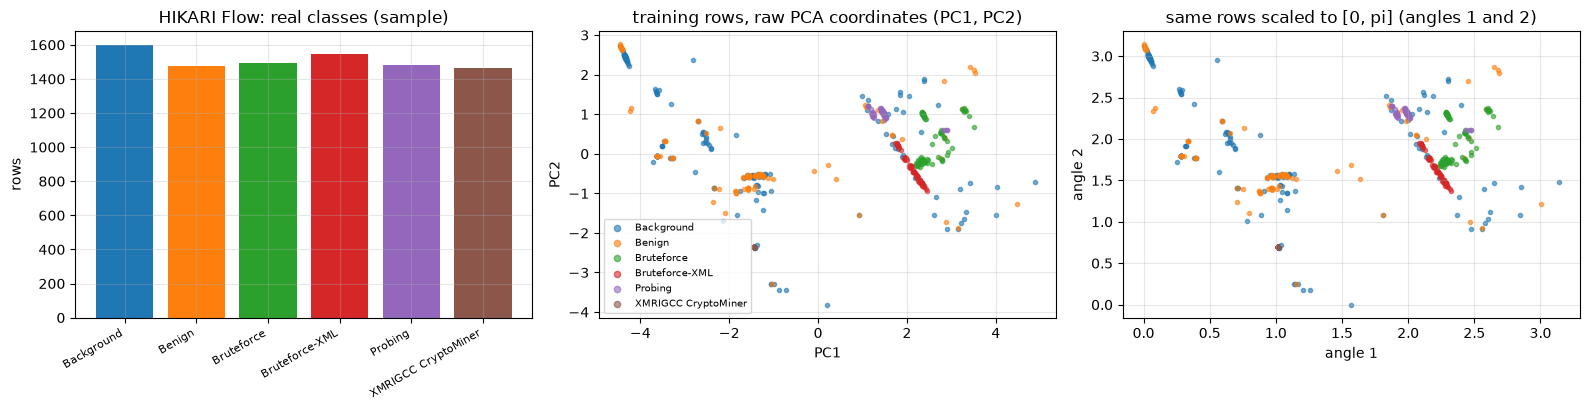

PCA explained variance of the 4 components: [0.557 0.184 0.109 0.063] | features kept by SelectKBest: ['flow_duration', 'pkts_total', 'bytes_total', 'pkts_per_sec', 'iat_mean', 'payload_mean', 'payload_std', 'port_https', 'port_high', 'init_window_fwd']
PHISHING (EMAIL CONTENT)
rows used here: 5,000 | engineered features: 12
features: urgent_kw, credential_kw, n_urls, url_max_len, text_len_log, entropy, exclam, upper_ratio, digit_ratio, html_tags, has_at_or_dollar, money_words
original labels / categories (counts in the sample): {'Phishing Email': 2500, 'Safe Email': 2500}
binary label (1 = phishing e-mail): {0: 2500, 1: 2500}


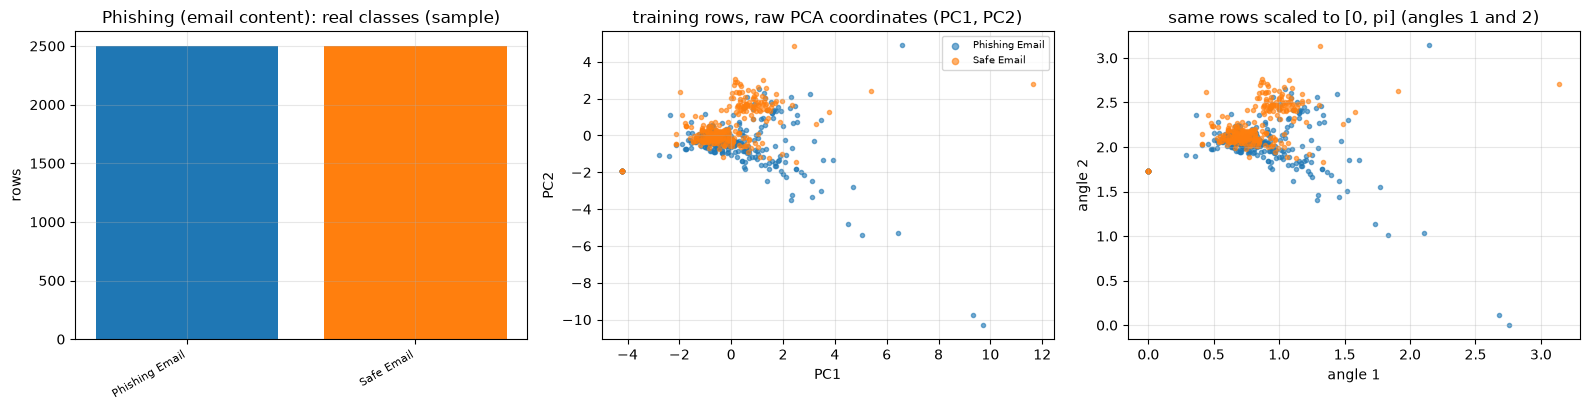

PCA explained variance of the 4 components: [0.247 0.168 0.107 0.106] | features kept by SelectKBest: ['urgent_kw', 'credential_kw', 'n_urls', 'url_max_len', 'text_len_log', 'entropy', 'exclam', 'digit_ratio', 'html_tags', 'money_words']
PHISHING (NETWORK PARAMETERS)
rows used here: 11,055 | engineered features: 30
features: having_ip_address, url_length, shortining_service, having_at_symbol, double_slash_redirecting, prefix_suffix, having_sub_domain, sslfinal_state, domain_registration_length, favicon, port, https_token, request_url, url_of_anchor, links_in_tags, sfh, submitting_to_email, abnormal_url, redirect, on_mouseover, rightclick, popupwindow, iframe, age_of_domain, dnsrecord, web_traffic, page_rank, google_index, links_pointing_to_page, statistical_report
original labels / categories (counts in the sample): {'legitimate site': 6157, 'phishing site': 4898}
binary label (1 = phishing site): {0: 6157, 1: 4898}


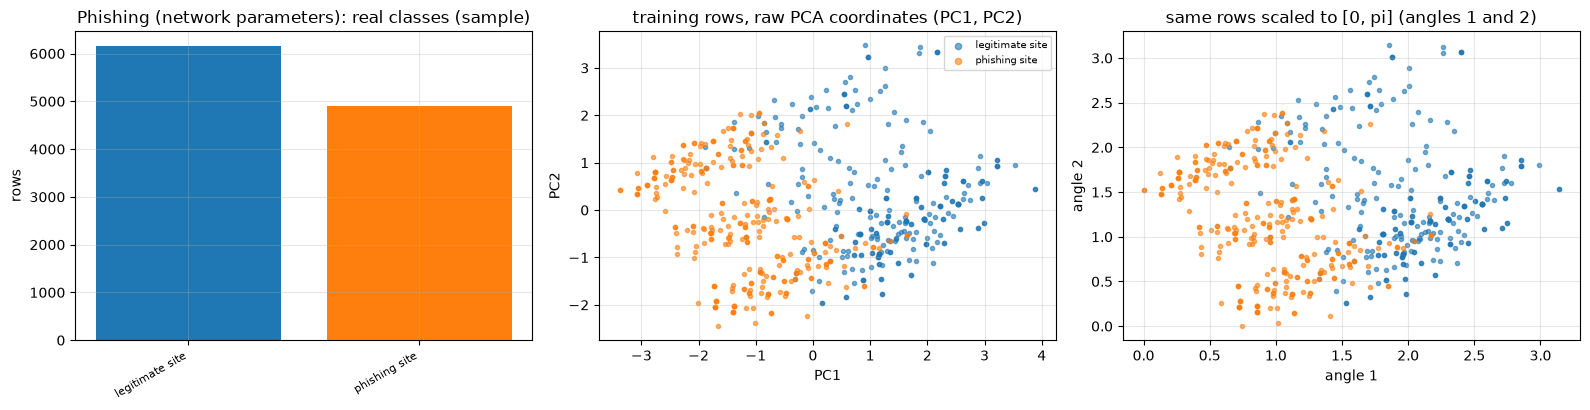

PCA explained variance of the 4 components: [0.255 0.141 0.111 0.103] | features kept by SelectKBest: ['prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'age_of_domain', 'web_traffic']
MALICIOUS URL
rows used here: 16,000 | engineered features: 15
features: url_length, url_entropy, host_length, n_subdomains, n_dots, n_hyphen, n_digits, digit_ratio, n_special, path_depth, has_ip, is_https, has_at, n_query, tld_length
original labels / categories (counts in the sample): {'benign': 8029, 'malicious': 7971}
binary label (1 = malicious URL): {0: 8029, 1: 7971}


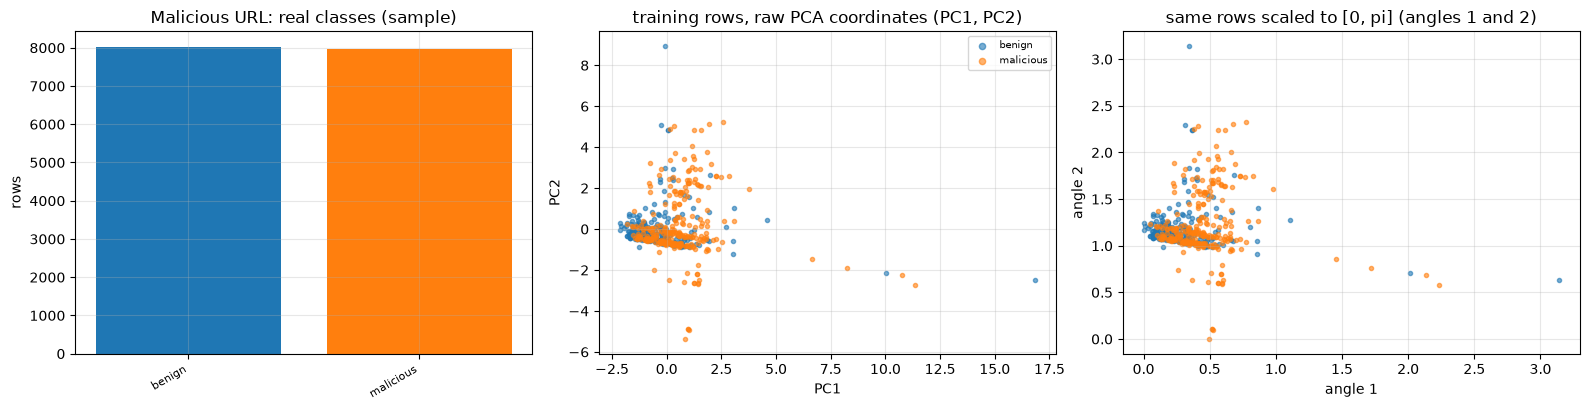

PCA explained variance of the 4 components: [0.239 0.173 0.135 0.115] | features kept by SelectKBest: ['host_length', 'n_subdomains', 'n_dots', 'n_hyphen', 'n_special', 'path_depth', 'has_ip', 'is_https', 'n_query', 'tld_length']


In [7]:
CAT_COLORS = plt.cm.tab10(np.arange(10))
for task in TASKS:
    d = DATA[task]; X, y, cat = d["X"], d["y"], d["cat"]
    print("=" * 100); print(task.upper())
    print(f"rows used here: {X.shape[0]:,} | engineered features: {X.shape[1]}")
    print("features:", ", ".join(X.columns))
    print("original labels / categories (counts in the sample):", {k: int(v) for k, v in pd.Series(cat).value_counts().items()})
    print("binary label (1 = " + d["pos"] + "):", {int(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()})
    if task == "HIKARI Flow": print("real category counts in the full 555k-flow HIKARI table:", HIK_COUNTS)
    V = prepare(task, SEED, VIS_TRAIN, N_TEST_Q)
    cats = sorted(pd.unique(cat)); col = {c: CAT_COLORS[i % 10] for i, c in enumerate(cats)}
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    vc = pd.Series(cat).value_counts().reindex(cats)
    ax[0].bar(range(len(cats)), vc.values, color=[col[c] for c in cats]); ax[0].set_xticks(range(len(cats))); ax[0].set_xticklabels(cats, rotation=30, ha="right", fontsize=8)
    ax[0].set_title(f"{task}: real classes (sample)"); ax[0].set_ylabel("rows")
    for c in cats:
        m = V["ctr"] == c
        ax[1].scatter(V["Rtr"][m, 0], V["Rtr"][m, 1], s=9, alpha=0.6, color=col[c], label=c)
        ax[2].scatter(V["Atr"][m, 0], V["Atr"][m, 1], s=9, alpha=0.6, color=col[c], label=c)
    ax[1].set_title("training rows, raw PCA coordinates (PC1, PC2)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=7, markerscale=1.5)
    ax[2].set_title("same rows scaled to [0, pi] (angles 1 and 2)"); ax[2].set_xlabel("angle 1"); ax[2].set_ylabel("angle 2")
    plt.tight_layout(); plt.show()
    print(f"PCA explained variance of the {N_QUBITS} components: {np.round(V['explained'], 3)} | features kept by SelectKBest: {V['selected']}")

## 3. Classical models of the paper (Figures 8-11)

The paper trains classical models first and reports bar charts without printed values. Its text makes **qualitative** statements that we can test:

* HIKARI: decision tree and gradient boosting are near perfect; naive Bayes is poor (Sect. 4.3).
* Phishing, network parameters: gradient boosting and random forest are best, naive Bayes worst (Sect. 4.3.1).
* Phishing, e-mail content: CatBoost and XGBoost exceed 98 %, extra trees and random forest are best, Gaussian naive Bayes underperforms (Sect. 4.4).
* Malicious URL: extra trees and random forest are the leading models, CatBoost and XGBoost are very effective (Sect. 4.5).

Each model is trained on a stratified split of the whole pool (at most `CLASSICAL_TRAIN_CAP` training rows) using **all** engineered features, with a 30 % test part.
For the e-mail task two extra rows use the paper's "keyword extraction" literally: a TF-IDF vocabulary of 5,000 words (fitted on the training e-mails only) fed to logistic regression and XGBoost.


HIKARI Flow: classical models on all 15 features (3000 training / 2717 test rows)


,acc,prec,rec,f1,seconds
Decision tree,0.9216,0.9419,0.9393,0.9406,0.3729
Naive Bayes,0.7398,0.7228,0.9833,0.8331,0.1001
Random forest,0.9466,0.9455,0.9755,0.9602,3.5546
Extra trees,0.9400,0.9459,0.9643,0.9550,2.9550
Gradient boosting,0.9558,0.9387,0.9983,0.9676,3.1620
XGBoost,0.9415,0.9436,0.9694,0.9563,68.9527
MLP,0.9577,0.9426,0.9967,0.9689,11.5428
SVC (RBF),0.9176,0.8894,0.9994,0.9412,0.7283



Phishing (email content): classical models on all 12 features (3000 training / 1500 test rows)


,acc,prec,rec,f1,seconds
Decision tree,0.7640,0.7475,0.7973,0.7716,0.3220
Naive Bayes,0.5613,0.7911,0.1667,0.2753,0.1838
Random forest,0.8253,0.8089,0.8520,0.8299,3.4742
Extra trees,0.8367,0.8266,0.8520,0.8391,2.6957
Gradient boosting,0.7980,0.8008,0.7933,0.7971,2.0470
XGBoost,0.8200,0.8077,0.8400,0.8235,49.0975
MLP,0.8033,0.8029,0.8040,0.8035,16.8440
SVC (RBF),0.8007,0.7979,0.8053,0.8016,2.1917
Logistic regression (TF-IDF words),0.9593,0.9563,0.9627,0.9595,0.3837
XGBoost (TF-IDF words),0.9500,0.9332,0.9693,0.9509,65.0107



Phishing (network parameters): classical models on all 30 features (3000 training / 3317 test rows)


,acc,prec,rec,f1,seconds
Decision tree,0.9295,0.9176,0.9238,0.9207,0.0574
Naive Bayes,0.6156,0.5356,0.9986,0.6972,0.0677
Random forest,0.9611,0.9615,0.9503,0.9559,1.3363
Extra trees,0.9596,0.9626,0.9456,0.9540,1.7504
Gradient boosting,0.9475,0.9494,0.9313,0.9402,1.9785
XGBoost,0.9608,0.9627,0.9483,0.9554,1.2523
MLP,0.9421,0.9383,0.9306,0.9344,11.3482
SVC (RBF),0.9427,0.9539,0.9150,0.9340,1.6644



Malicious URL: classical models on all 15 features (3000 training / 4800 test rows)


,acc,prec,rec,f1,seconds
Decision tree,0.7931,0.7888,0.7984,0.7936,0.1945
Naive Bayes,0.6362,0.9412,0.2877,0.4407,0.1502
Random forest,0.8565,0.8505,0.8637,0.8570,2.0542
Extra trees,0.8608,0.8588,0.8624,0.8606,1.8154
Gradient boosting,0.8415,0.8459,0.8335,0.8397,2.6433
XGBoost,0.8438,0.8386,0.8499,0.8442,14.0912
MLP,0.8502,0.8585,0.8373,0.8478,11.4498
SVC (RBF),0.8010,0.7905,0.8172,0.8036,2.6070


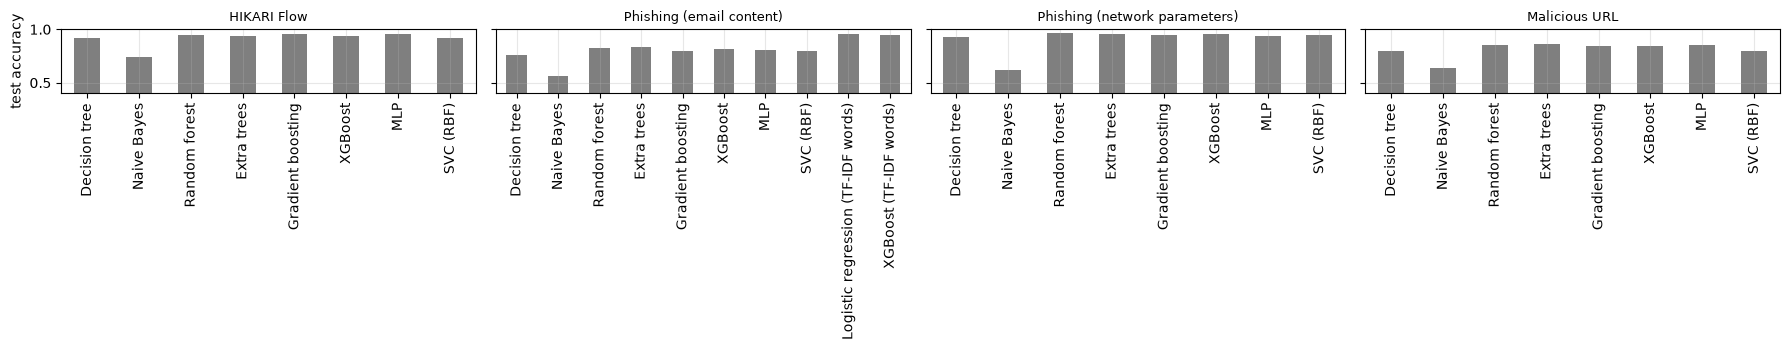

In [8]:
def metrics_of(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred), prec=precision_score(y_true, y_pred, zero_division=0),
                rec=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

def classical_models(seed):
    return {"Decision tree": DecisionTreeClassifier(random_state=seed),
            "Naive Bayes": GaussianNB(),
            "Random forest": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
            "Extra trees": ExtraTreesClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
            "Gradient boosting": GradientBoostingClassifier(random_state=seed),
            "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, random_state=seed, n_jobs=2, eval_metric="logloss"),
            "MLP": make_pipeline(StandardScaler(), MLPClassifier((32, 16), max_iter=300, random_state=seed)),
            "SVC (RBF)": make_pipeline(StandardScaler(), SVC(random_state=seed))}

CLASSICAL = {}      # task -> DataFrame (model x metrics)
for task in TASKS:
    d = DATA[task]; X, y = d["X"], d["y"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
    if len(Xtr) > CLASSICAL_TRAIN_CAP:
        keep = np.random.default_rng(SEED).choice(len(Xtr), CLASSICAL_TRAIN_CAP, replace=False); Xtr, ytr = Xtr.iloc[keep], ytr[keep]
    rows = {}
    for name, m in classical_models(SEED).items():
        t = time.perf_counter(); m.fit(Xtr, ytr); rows[name] = {**metrics_of(yte, m.predict(Xte)), "seconds": time.perf_counter() - t}
    if task == "Phishing (email content)":
        # extra text baselines: the paper's "keyword extraction" taken literally (TF-IDF words, vocabulary fitted on the training e-mails only)
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.linear_model import LogisticRegression
        txt = pem["Email Text"].astype(str); tfv = TfidfVectorizer(max_features=5000, stop_words="english", sublinear_tf=True).fit(txt.loc[Xtr.index])
        Ttr, Tte = tfv.transform(txt.loc[Xtr.index]), tfv.transform(txt.loc[Xte.index])
        for name, m in {"Logistic regression (TF-IDF words)": LogisticRegression(max_iter=1000),
                        "XGBoost (TF-IDF words)": XGBClassifier(n_estimators=200, max_depth=6, tree_method="hist", random_state=SEED, n_jobs=2, eval_metric="logloss")}.items():
            t = time.perf_counter(); m.fit(Ttr, ytr); rows[name] = {**metrics_of(yte, m.predict(Tte)), "seconds": time.perf_counter() - t}
    CLASSICAL[task] = pd.DataFrame(rows).T
    print(f"\n{task}: classical models on all {X.shape[1]} features ({len(Xtr)} training / {len(Xte)} test rows)")
    display(CLASSICAL[task].round(4))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for a, task in zip(ax, TASKS):
    CLASSICAL[task]["acc"].plot.bar(ax=a, color="tab:gray"); a.set_title(task, fontsize=9); a.set_ylim(0.4, 1.0); a.set_ylabel("test accuracy")
plt.tight_layout(); plt.show()

## 4. The quantum building blocks

All circuits are built with the Qiskit circuit library and run on exact (noiseless) state-vector simulators. A **feature map** writes the four angles of a sample into four qubits.
A **bandwidth** `bw` multiplies the angles before encoding (a kernel-width knob tuned by cross-validation on the training rows in the "after" configuration; `bw = 1` in the "before" configuration).

* **VQC**: `feature_map` + `ansatz`, Qiskit's `VQC` (sampler read-out, parity of the bit string gives the class), COBYLA.
* **QNN**: the same circuit read out as the expectation value of `Z x Z x Z x Z` (`EstimatorQNN` + `NeuralNetworkClassifier`, squared loss, COBYLA); the sign is the class.
* **QCNN**: feature map, then a convolution block shared by four neighbouring pairs, a pooling block (4 to 2 qubits), a second convolution and pooling (2 to 1 qubit) and a `Z` read-out on the last qubit; 12 trainable parameters, shared across the layer as in a convolutional network.
* **QSVC**: SVM on the fidelity kernel `|<phi(a)|phi(b)>|^2` of the feature map (`FidelityStatevectorKernel` inside Qiskit's `QSVC`).
* **Pegasos-QSVC**: the same kernel, trained with Pegasos (stochastic sub-gradient descent, regularisation `C`, `num_steps` = tau).

In [9]:
def feature_map(kind, n, reps):
    # "Z": product encoding without entanglement (the 'before' default). "ZZ": entangling pairwise phases (the 'after' choice).
    return z_feature_map(n, reps=reps) if kind == "Z" else zz_feature_map(n, reps=reps, entanglement="linear")

def conv_block(p):
    t = QuantumCircuit(2); t.rz(-np.pi / 2, 1); t.cx(1, 0); t.rz(p[0], 0); t.ry(p[1], 1); t.cx(0, 1); t.ry(p[2], 1); t.cx(1, 0); t.rz(np.pi / 2, 0); return t
def pool_block(p):
    t = QuantumCircuit(2); t.rz(-np.pi / 2, 1); t.cx(1, 0); t.rz(p[0], 0); t.ry(p[1], 1); t.cx(0, 1); t.ry(p[2], 1); return t

def qcnn_ansatz(n=4):
    # 4 qubits: C1 on (0,1),(2,3),(1,2),(3,0) -> P1 (0->1),(2->3) -> C2 on (1,3) -> P1' (1->3); read-out qubit 3. 12 shared parameters.
    assert n == 4
    w = ParameterVector("w", 12); qc = QuantumCircuit(4, name="QCNN")
    for a, b in [(0, 1), (2, 3), (1, 2), (3, 0)]: qc.compose(conv_block(w[0:3]), [a, b], inplace=True)
    qc.barrier()
    for a, b in [(0, 1), (2, 3)]: qc.compose(pool_block(w[3:6]), [a, b], inplace=True)
    qc.barrier(); qc.compose(conv_block(w[6:9]), [1, 3], inplace=True); qc.compose(pool_block(w[9:12]), [1, 3], inplace=True)
    return qc

STAGES = {   # CHOICE: see the table "What follows the paper and what had to be chosen"
    "before": dict(fm="Z",  fm_reps=1, an_reps=1, iters=BEFORE_ITERS, peg_steps=PEG_STEPS_BEFORE),
    "after":  dict(fm="ZZ", fm_reps=2, an_reps=2, iters=AFTER_ITERS,  peg_steps=PEG_STEPS_AFTER),
}
def vqc_parts(stage, n=N_QUBITS):
    s = STAGES[stage]; return feature_map(s["fm"], n, s["fm_reps"]), real_amplitudes(n, reps=s["an_reps"])
def qnn_circuit(stage, kind, n=N_QUBITS):
    # returns (full circuit, input parameters, weight parameters)
    s = STAGES[stage]; fm = feature_map(s["fm"], n, 1 if kind == "QCNN" else s["fm_reps"])
    an = qcnn_ansatz(n) if kind == "QCNN" else real_amplitudes(n, reps=s["an_reps"])
    qc = QuantumCircuit(n); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)
    return qc, list(fm.parameters), list(an.parameters)
def observable(kind, n=N_QUBITS):
    return SparsePauliOp("Z" + "I" * (n - 1)) if kind == "QCNN" else SparsePauliOp("Z" * n)

for stage in STAGES:
    fm, an = vqc_parts(stage); print(f"{stage:6s} VQC/QNN: feature map {fm.num_parameters} inputs, ansatz {an.num_parameters} trainable parameters")
print("QCNN ansatz trainable parameters:", qcnn_ansatz().num_parameters)

before VQC/QNN: feature map 4 inputs, ansatz 8 trainable parameters
after  VQC/QNN: feature map 4 inputs, ansatz 12 trainable parameters
QCNN ansatz trainable parameters: 12


In [10]:
RESULTS, FITTED = [], {}      # one dict per (task, model, stage, seed); FITTED keeps the last fitted model of each kind for the circuit check

def record(task, model, stage, seed, y_true, y_pred, seconds, extra=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
    RESULTS.append(dict(task=task, model=model, stage=stage, seed=seed, **metrics_of(y_true, y_pred), tn=tn, fp=fp, fn=fn, tp=tp, seconds=seconds, **(extra or {})))

def init_point(seed, k): return np.random.default_rng(seed).uniform(-np.pi, np.pi, k)

def fit_vqc(D, stage, seed, bw=1.0, key=None):
    fm, an = vqc_parts(stage); loss = []
    algorithm_globals.random_seed = seed
    clf = VQC(feature_map=fm, ansatz=an, optimizer=COBYLA(maxiter=STAGES[stage]["iters"]), sampler=StatevectorSampler(seed=seed),
              initial_point=init_point(seed, an.num_parameters), callback=lambda w, f: loss.append(f))
    t = time.perf_counter(); clf.fit(D["Atr"] * bw, D["ytr"]); pred = np.asarray(clf.predict(D["Ate"] * bw))
    pred = pred.argmax(1) if pred.ndim == 2 else pred
    FITTED[(key or "VQC", stage)] = clf; return pred, time.perf_counter() - t, loss

def fit_qnn(D, stage, seed, kind, bw=1.0):
    qc, ins, ws = qnn_circuit(stage, kind); loss = []
    qnn = EstimatorQNN(circuit=qc, input_params=ins, weight_params=ws, observables=observable(kind), estimator=StatevectorEstimator(), input_gradients=False)
    algorithm_globals.random_seed = seed
    clf = NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=STAGES[stage]["iters"]), loss="squared_error", one_hot=False,
                                  initial_point=init_point(seed, len(ws)), callback=lambda w, f: loss.append(f))
    t = time.perf_counter(); clf.fit(D["Atr"] * bw, 2 * D["ytr"] - 1); pred = (np.asarray(clf.predict(D["Ate"] * bw)).ravel() > 0).astype(int)
    FITTED[(kind, stage)] = clf; return pred, time.perf_counter() - t, loss

def kernel_obj(stage, bw):
    return FidelityStatevectorKernel(feature_map=feature_map(STAGES[stage]["fm"], N_QUBITS, STAGES[stage]["fm_reps"]), auto_clear_cache=False)

def tune_kernel(D, stage, seed):
    # bandwidth and C chosen by 5-fold cross-validation on the TRAINING rows only (precomputed-kernel SVM, cheap); the test set is never touched
    skf = StratifiedKFold(5, shuffle=True, random_state=seed); best = (-1.0, None, None); y = D["ytr"]
    for bw in BW_GRID:
        K = kernel_obj(stage, bw).evaluate(D["Atr"] * bw)
        for C in C_GRID:
            acc = np.mean([SVC(kernel="precomputed", C=C).fit(K[np.ix_(a, a)], y[a]).score(K[np.ix_(v, a)], y[v]) for a, v in skf.split(K, y)])
            if acc > best[0] + 1e-12: best = (float(acc), bw, C)       # ties keep the smaller bandwidth
    return best

def fit_qsvc(D, stage, seed, bw, C):
    k = kernel_obj(stage, bw); algorithm_globals.random_seed = seed
    clf = QSVC(quantum_kernel=k, C=C); t = time.perf_counter()
    clf.fit(D["Atr"] * bw, D["ytr"]); pred = clf.predict(D["Ate"] * bw)
    FITTED[("QSVC", stage)] = (k, clf); return pred, time.perf_counter() - t

def fit_pegasos(D, stage, seed, bw, C=1000):
    k = kernel_obj(stage, bw)
    clf = PegasosQSVC(quantum_kernel=k, C=C, num_steps=STAGES[stage]["peg_steps"], seed=seed); t = time.perf_counter()
    clf.fit(D["Atr"] * bw, D["ytr"]); pred = clf.predict(D["Ate"] * bw)
    FITTED[("Pegasos", stage)] = (k, clf); return pred, time.perf_counter() - t

In [11]:
# Sanity check of the QSVC: the Qiskit QSVC and a hand-made |<phi(a)|phi(b)>|^2 kernel fed to an SVM must agree
from qiskit.quantum_info import Statevector
Dchk = prepare(TASKS[3], SEED, 20, 10); fmz = feature_map("ZZ", N_QUBITS, 2)
sv = lambda x: Statevector(fmz.assign_parameters(dict(zip(fmz.parameters, x)))).data
S = np.array([sv(x) for x in Dchk["Atr"]]); K_hand = np.abs(S.conj() @ S.T) ** 2
K_qiskit = FidelityStatevectorKernel(feature_map=fmz).evaluate(Dchk["Atr"])
print("hand-made kernel equals Qiskit's FidelityStatevectorKernel:", np.allclose(K_hand, K_qiskit, atol=1e-8), "| diagonal all ones:", np.allclose(np.diag(K_hand), 1))

hand-made kernel equals Qiskit's FidelityStatevectorKernel: True | diagonal all ones: True


## 5. BB84 quantum key distribution (Figures 2-6, Sect. 3.2)

Alice draws random bits and random bases (rectilinear or diagonal), encodes each bit in one qubit (`X` for a 1; `H` to switch to the diagonal basis), Bob measures every qubit in a random basis,
and both keep only the positions where the bases agree (the *sifted key*). The **quantum bit error rate** (QBER) is the fraction of sifted positions where the bits differ; the paper's
Eq. 4 defines an error rate D and aborts when it exceeds a threshold (value not given; we use the usual 11 %).

* **No eavesdropper**: the sifted keys should be identical (QBER 0, "100 % key match", Fig. 4).
* **Intercept-resend eavesdropper (Eve)**: she measures each qubit in a random basis and re-sends what she found. When her basis is wrong (half the time) the state is disturbed and Bob errs half of the
  time he uses the same basis as Alice, so the expected QBER is 25 % (Figs. 5-6).
* **Noisy channel without Eve** (the paper tests "realistic noisy conditions"): depolarising error on the gates and read-out error; the QBER stays well below the threshold, so nobody is accused.

Eve's measure, reset and re-send is a dynamic circuit (`measure`, `reset`, `if_test`) executed by Aer. Each circuit has 10 qubits, as in the paper's Figure 6.

In [12]:
def bb84_circuit(a_bits, a_bases, b_bases, eve_bases=None):
    n = len(a_bits); q = QuantumRegister(n, "q"); cb = ClassicalRegister(n, "bob"); regs = [q, cb]
    ce = ClassicalRegister(n, "eve") if eve_bases is not None else None
    if ce is not None: regs.append(ce)
    qc = QuantumCircuit(*regs)
    for i in range(n):                                   # Alice: bit -> X, basis -> H
        if a_bits[i]: qc.x(q[i])
        if a_bases[i]: qc.h(q[i])
    qc.barrier()
    if eve_bases is not None:                            # Eve: intercept in a random basis, measure, re-send
        for i in range(n):
            if eve_bases[i]: qc.h(q[i])
            qc.measure(q[i], ce[i]); qc.reset(q[i])
            with qc.if_test((ce[i], 1)): qc.x(q[i])
            if eve_bases[i]: qc.h(q[i])
        qc.barrier()
    for i in range(n):                                   # Bob: measure in his basis
        if b_bases[i]: qc.h(q[i])
        qc.measure(q[i], cb[i])
    return qc

def noise_model(p_gate=0.02, p_ro=0.01):
    nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(p_gate, 1), ["x", "h"])
    nm.add_all_qubit_readout_error(ReadoutError([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])); return nm

def run_bb84(scenario, n_circuits=BB84_CIRCUITS, n=BB84_BITS_PER_CIRCUIT, seed=SEED):
    g = np.random.default_rng(seed); eve = scenario == "eavesdropper"
    backend = AerSimulator(noise_model=noise_model()) if scenario == "noisy channel" else AerSimulator()
    circs, meta = [], []
    for _ in range(n_circuits):
        a, ab, bb = g.integers(0, 2, n), g.integers(0, 2, n), g.integers(0, 2, n); eb = g.integers(0, 2, n) if eve else None
        circs.append(bb84_circuit(a, ab, bb, eb)); meta.append((a, ab, bb))
    res = backend.run(transpile(circs, backend), shots=1, seed_simulator=seed).result()
    alice_key, bob_key = [], []
    for j, (a, ab, bb) in enumerate(meta):
        bits = list(res.get_counts(j))[0].split()[-1] if eve else list(res.get_counts(j))[0]       # Bob's register is the first (right-most) one
        bob = np.array([int(c) for c in bits[::-1]])
        keep = ab == bb; alice_key += list(a[keep]); bob_key += list(bob[keep])
    alice_key, bob_key = np.array(alice_key), np.array(bob_key); qber = float(np.mean(alice_key != bob_key))
    return dict(scenario=scenario, qubits_sent=n_circuits * n, sifted_key_bits=len(alice_key), mismatches=int((alice_key != bob_key).sum()),
                QBER=qber, key_match=1 - qber, abort=bool(qber > QBER_THRESHOLD))

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
BB84 =pd.DataFrame([run_bb84(s) for s in ["no eavesdropper", "eavesdropper", "noisy channel"]]).set_index("scenario")
display(BB84.round(4))

,qubits_sent,sifted_key_bits,mismatches,QBER,key_match,abort
scenario,,,,,,
no eavesdropper,4000,2021,0,0.0000,1.0000,False
eavesdropper,4000,2027,522,0.2575,0.7425,True
noisy channel,4000,2021,56,0.0277,0.9723,False


## Quantum Circuit Architecture

The drawings below are produced from the very same builder functions that the training code calls (`vqc_parts`, `qnn_circuit`, `qcnn_ansatz`, `bb84_circuit`).
After training (Section 6) a cell asserts that the circuit stored inside each fitted Qiskit model has the same gates and parameter count as the one drawn here.
The paper gives no circuit details for the QML models (only a generic BB84 circuit, its Figure 3), so qubit count, repetitions, entanglement and read-out are documented choices:

* 4 qubits, one PCA angle per qubit, rotation-angle encoding.
* "before": `z_feature_map` (H then P(2x) per qubit, 1 repetition) + `real_amplitudes` (RY layers with CX in reverse-linear pattern, 1 repetition).
* "after": `zz_feature_map` (adds pairwise phases, linear entanglement, 2 repetitions) + `real_amplitudes` (2 repetitions).
* VQC read-out: all qubits measured, parity of the bit string is the class. QNN read-out: expectation of `ZZZZ`. QCNN read-out: expectation of `Z` on qubit 3.
* The QSVC and Pegasos kernels use only the feature map (`|<phi(a)|phi(b)>|^2`, from the two state vectors), so the feature-map circuit is the executed circuit.

VQC 'before' (z_feature_map x1 + real_amplitudes x1, parity read-out): qubits=4 | depth=8 | trainable parameters=8 | data-input parameters=4 | gates={'ry': 8, 'h': 4, 'p': 4, 'measure': 4, 'cx': 3, 'barrier': 1}


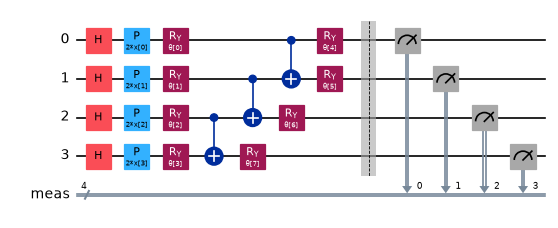

VQC 'after' (zz_feature_map x2 + real_amplitudes x2, parity read-out): qubits=4 | depth=28 | trainable parameters=12 | data-input parameters=4 | gates={'cx': 18, 'p': 14, 'ry': 12, 'h': 8, 'measure': 4, 'barrier': 1}


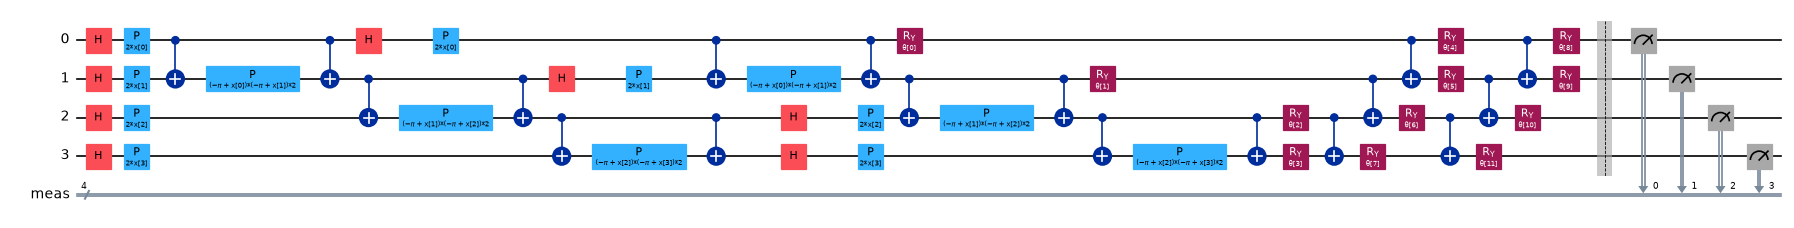

QNN 'after' (read-out <ZZZZ>): qubits=4 | depth=27 | trainable parameters=12 | data-input parameters=4 | gates={'cx': 18, 'p': 14, 'ry': 12, 'h': 8}


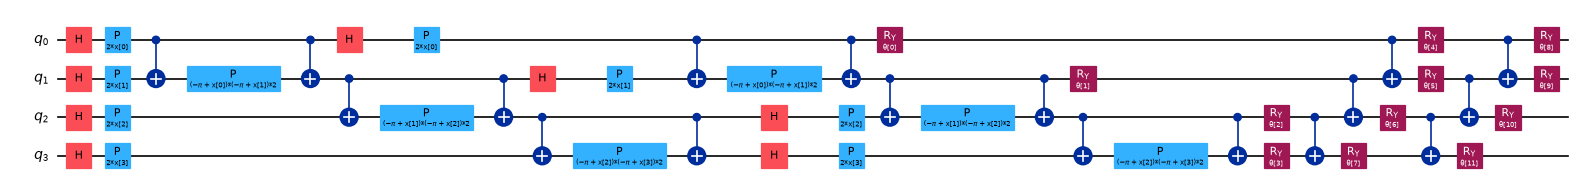

QCNN 'after' (read-out <ZIII>): qubits=4 | depth=41 | trainable parameters=12 | data-input parameters=4 | gates={'cx': 27, 'rz': 21, 'ry': 16, 'p': 7, 'h': 4, 'barrier': 2}


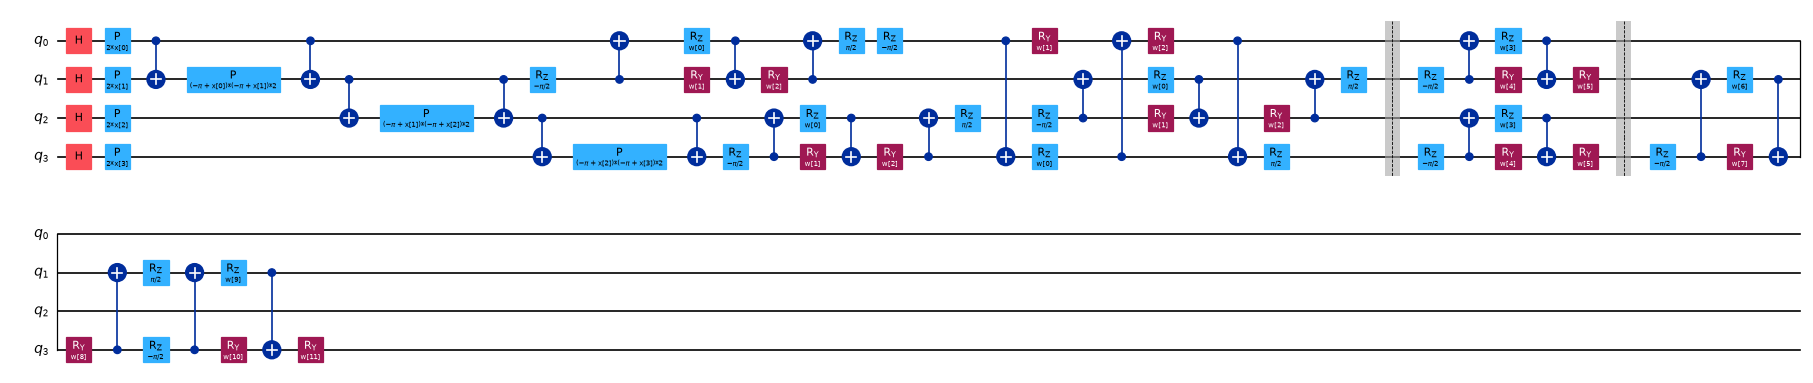

QNN 'before' has the same gates as the VQC 'before' drawing (without the final measurement): True
Kernel circuit of QSVC / Pegasos 'before' (z_feature_map x1): qubits=4 | depth=2 | trainable parameters=0 | data-input parameters=4 | gates={'h': 4, 'p': 4}


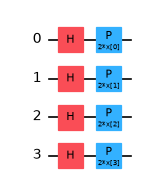

Kernel circuit of QSVC / Pegasos 'after' (zz_feature_map x2): qubits=4 | depth=19 | trainable parameters=0 | data-input parameters=4 | gates={'p': 14, 'cx': 12, 'h': 8}


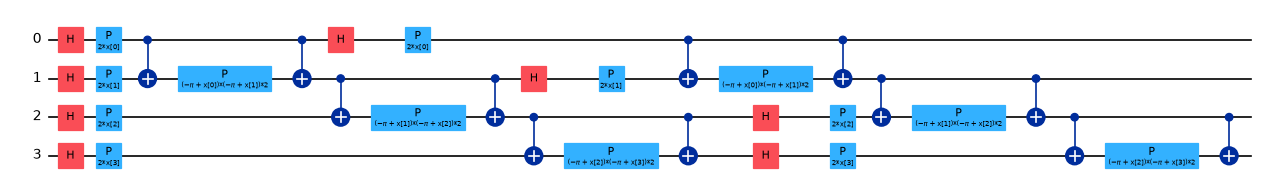

BB84 with intercept-resend eavesdropper (the dynamic circuit executed in Section 5): qubits=10 | depth=9 | trainable parameters=0 | gates={'measure': 20, 'h': 16, 'reset': 10, 'if_else': 10, 'x': 5, 'barrier': 2}


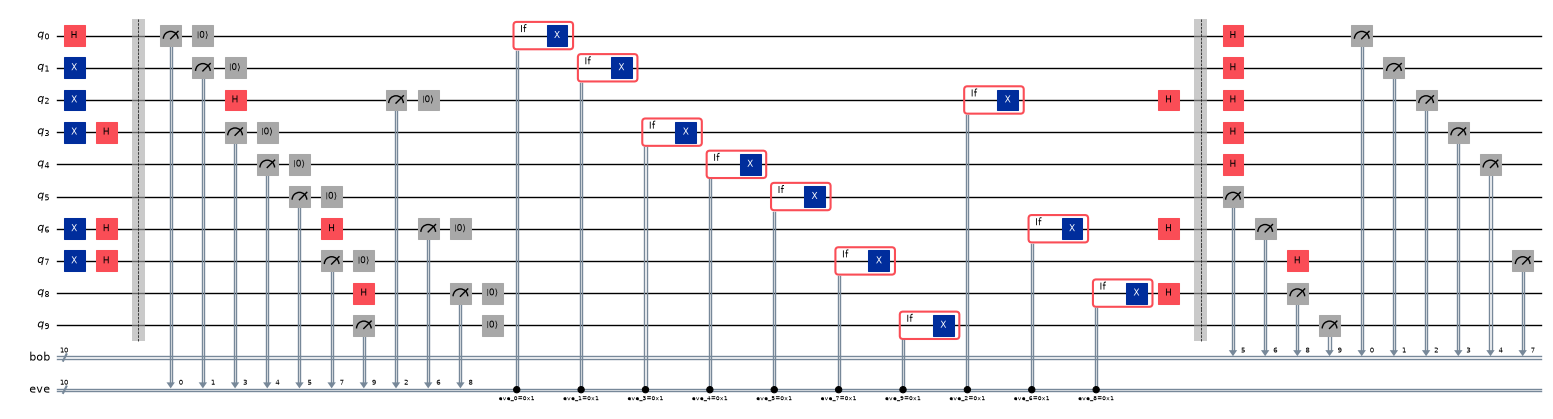

In [13]:
def show(name, qc, n_train_params, n_input_params, measure=False):
    c = qc.copy()
    if measure: c.measure_all()       # the Sampler adds exactly this read-out when the VQC is evaluated
    print(f"{name}: qubits={c.num_qubits} | depth={c.depth()} | trainable parameters={n_train_params} | data-input parameters={n_input_params} | gates={dict(c.count_ops())}")
    fig = c.draw("mpl", fold=45, scale=0.6); display(fig); plt.close(fig)
fm_b, an_b = vqc_parts("before"); fm_a, an_a = vqc_parts("after")
show("VQC 'before' (z_feature_map x1 + real_amplitudes x1, parity read-out)", fm_b.compose(an_b), an_b.num_parameters, fm_b.num_parameters, measure=True)
show("VQC 'after' (zz_feature_map x2 + real_amplitudes x2, parity read-out)", fm_a.compose(an_a), an_a.num_parameters, fm_a.num_parameters, measure=True)
for kind in ["QNN", "QCNN"]:
    qc, ins, ws = qnn_circuit("after", kind)
    show(f"{kind} 'after' (read-out <{observable(kind).paulis[0]}>)", qc, len(ws), len(ins))
qc, ins, ws = qnn_circuit("before", "QNN"); print("QNN 'before' has the same gates as the VQC 'before' drawing (without the final measurement):", qc.count_ops() == fm_b.compose(an_b).count_ops())
show("Kernel circuit of QSVC / Pegasos 'before' (z_feature_map x1)", feature_map("Z", N_QUBITS, 1), 0, N_QUBITS)
show("Kernel circuit of QSVC / Pegasos 'after' (zz_feature_map x2)", feature_map("ZZ", N_QUBITS, 2), 0, N_QUBITS)

g0 = np.random.default_rng(1); n = BB84_BITS_PER_CIRCUIT
demo = bb84_circuit(g0.integers(0, 2, n), g0.integers(0, 2, n), g0.integers(0, 2, n), g0.integers(0, 2, n))
print(f"BB84 with intercept-resend eavesdropper (the dynamic circuit executed in Section 5): qubits={demo.num_qubits} | depth={demo.depth()} | trainable parameters=0 | gates={dict(demo.count_ops())}")
fig = demo.draw("mpl", fold=-1, scale=0.5); display(fig); plt.close(fig)

## 6. Train the five QML models and the like-for-like classical baselines

For every task, every seed and both stages, the same class-balanced sample (`N_TRAIN_Q` training and `N_TEST_Q` test rows, stratified) is used by all models. The classical
baselines (random forest, gradient boosting, RBF-SVC) see exactly the same four angles. In the "after" stage the kernel bandwidth and `C` are first chosen by 5-fold cross-validation on the training rows (the test rows are never used);
the same bandwidth is then also applied to the angles of the VQC, QNN, QCNN and Pegasos models.

In [14]:
LOSS = {}
def run_all(task, seed):
    D = prepare(task, seed, N_TRAIN_Q, N_TEST_Q); yte = D["yte"]
    # like-for-like classical baselines on the same four angles
    for name, m in {"RF (4 angles)": RandomForestClassifier(n_estimators=200, random_state=seed), "GB (4 angles)": GradientBoostingClassifier(random_state=seed),
                    "SVC-RBF (4 angles)": SVC(random_state=seed)}.items():
        t = time.perf_counter(); m.fit(D["Atr"], D["ytr"]); record(task, name, "classical", seed, yte, m.predict(D["Ate"]), time.perf_counter() - t)
    val_acc, bw, C = tune_kernel(D, "after", seed)
    for stage in ["before", "after"]:
        b = bw if stage == "after" else 1.0
        pred, sec, loss = fit_vqc(D, stage, seed, b); record(task, "VQC", stage, seed, yte, pred, sec); LOSS[(task, "VQC", stage, seed)] = loss
        pred, sec = fit_qsvc(D, stage, seed, b, C if stage == "after" else 1); record(task, "QSVC", stage, seed, yte, pred, sec, dict(bw=b, C=C if stage == "after" else 1, cv_acc=val_acc if stage == "after" else np.nan))
        pred, sec, loss = fit_qnn(D, stage, seed, "QNN", b); record(task, "QNN", stage, seed, yte, pred, sec); LOSS[(task, "QNN", stage, seed)] = loss
        pred, sec = fit_pegasos(D, stage, seed, b); record(task, "QSVC-Pegasos", stage, seed, yte, pred, sec)
        pred, sec, loss = fit_qnn(D, stage, seed, "QCNN", b); record(task, "QCNN", stage, seed, yte, pred, sec); LOSS[(task, "QCNN", stage, seed)] = loss
    return D, bw, C

PREPARED = {}
t_all = time.perf_counter()
for seed in SEEDS:
    for task in TASKS:
        t = time.perf_counter(); PREPARED[(task, seed)] = run_all(task, seed)
        r = pd.DataFrame([x for x in RESULTS if x["task"] == task and x["seed"] == seed])
        print(f"seed {seed} | {task:30s} | {time.perf_counter() - t:5.0f} s | bandwidth {PREPARED[(task, seed)][1]} C {PREPARED[(task, seed)][2]} | after-accuracy: " +
              ", ".join(f"{m} {a:.2f}" for m, a in r[r.stage == "after"].set_index("model")["acc"].items()))
print(f"total {time.perf_counter() - t_all:.0f} s")
R = pd.DataFrame(RESULTS)

seed 42 | HIKARI Flow                    |   519 s | bandwidth 0.5 C 100 | after-accuracy: VQC 0.86, QSVC 0.87, QNN 0.72, QSVC-Pegasos 0.73, QCNN 0.81


seed 42 | Phishing (email content)       |   606 s | bandwidth 0.25 C 10 | after-accuracy: VQC 0.64, QSVC 0.66, QNN 0.62, QSVC-Pegasos 0.66, QCNN 0.53


seed 42 | Phishing (network parameters)  |   691 s | bandwidth 0.25 C 100 | after-accuracy: VQC 0.66, QSVC 0.72, QNN 0.70, QSVC-Pegasos 0.58, QCNN 0.66


seed 42 | Malicious URL                  |   552 s | bandwidth 0.25 C 1 | after-accuracy: VQC 0.71, QSVC 0.81, QNN 0.74, QSVC-Pegasos 0.76, QCNN 0.64


seed 43 | HIKARI Flow                    |   588 s | bandwidth 0.25 C 10 | after-accuracy: VQC 0.78, QSVC 0.82, QNN 0.76, QSVC-Pegasos 0.78, QCNN 0.62


seed 43 | Phishing (email content)       |   569 s | bandwidth 0.25 C 1 | after-accuracy: VQC 0.68, QSVC 0.74, QNN 0.57, QSVC-Pegasos 0.58, QCNN 0.59


seed 43 | Phishing (network parameters)  |   606 s | bandwidth 0.5 C 10 | after-accuracy: VQC 0.77, QSVC 0.79, QNN 0.61, QSVC-Pegasos 0.72, QCNN 0.62


seed 43 | Malicious URL                  |   522 s | bandwidth 0.25 C 10 | after-accuracy: VQC 0.67, QSVC 0.75, QNN 0.64, QSVC-Pegasos 0.52, QCNN 0.55
total 4654 s


In [15]:
# The circuits stored inside the fitted Qiskit models are the ones drawn in "Quantum Circuit Architecture"
vqc_a = FITTED[("VQC", "after")]; vqc_b = FITTED[("VQC", "before")]
fm_b, an_b = vqc_parts("before"); fm_a, an_a = vqc_parts("after")
for name, clf, (fm, an) in [("VQC before", vqc_b, (fm_b, an_b)), ("VQC after", vqc_a, (fm_a, an_a))]:
    drawn = fm.compose(an); ex = clf.neural_network.circuit        # the Sampler appends the measurement of all qubits when it runs
    assert ex.count_ops() == drawn.count_ops() and ex.num_parameters == drawn.num_parameters, name
    print(f"{name}: executed circuit == drawn circuit | gates {dict(ex.count_ops())} | parameters {ex.num_parameters} | depth {ex.depth()}")
for kind in ["QNN", "QCNN"]:
    for stage in ["before", "after"]:
        qc, ins, ws = qnn_circuit(stage, kind); ex = FITTED[(kind, stage)].neural_network.circuit
        assert ex.count_ops() == qc.count_ops() and ex.num_parameters == qc.num_parameters; print(f"{kind} {stage}: executed circuit == drawn circuit | parameters {ex.num_parameters} | depth {ex.depth()}")
for name in ["QSVC", "Pegasos"]:
    for stage in ["before", "after"]:
        k = FITTED[(name, stage)][0]; s = STAGES[stage]; assert k.feature_map.count_ops() == feature_map(s["fm"], N_QUBITS, s["fm_reps"]).count_ops()
print("kernel feature maps == drawn feature maps")

VQC before: executed circuit == drawn circuit | gates {'ry': 8, 'h': 4, 'p': 4, 'cx': 3} | parameters 12 | depth 7
VQC after: executed circuit == drawn circuit | gates {'cx': 18, 'p': 14, 'ry': 12, 'h': 8} | parameters 16 | depth 27
QNN before: executed circuit == drawn circuit | parameters 12 | depth 7
QNN after: executed circuit == drawn circuit | parameters 16 | depth 27
QCNN before: executed circuit == drawn circuit | parameters 16 | depth 32
QCNN after: executed circuit == drawn circuit | parameters 16 | depth 41
kernel feature maps == drawn feature maps


## 7. Table 2 of the paper, rebuilt

Paper Table 2 gives one "score" per model, task and stage. We take the score to be the test-set accuracy and show the F1 score next to it. The tolerance for "reproduced" is 0.02.
Our test sets have only `N_TEST_Q` rows, so one error is worth 0.01 (FAST) or 0.005 (full): differences of a couple of hundredths are within sampling noise.

,task,model,paper_before,ours_before,verdict_before,paper_after,ours_after,ours_after_std,ours_after_F1,verdict_after
0,HIKARI Flow,VQC,0.64,0.577,not reached,0.99,0.822,0.060,0.847,not reached
1,HIKARI Flow,QSVC,0.53,0.842,exceeded,0.97,0.845,0.035,0.862,not reached
2,HIKARI Flow,QNN,0.78,0.765,reproduced,0.95,0.740,0.021,0.738,not reached
3,HIKARI Flow,QSVC-Pegasos,0.63,0.615,reproduced,0.98,0.755,0.028,0.696,not reached
4,HIKARI Flow,QCNN,0.57,0.765,exceeded,0.99,0.715,0.127,0.740,not reached
5,Phishing (email content),VQC,0.61,0.472,not reached,0.97,0.658,0.025,0.648,not reached
6,Phishing (email content),QSVC,0.66,0.710,exceeded,0.98,0.698,0.060,0.701,not reached
7,Phishing (email content),QNN,0.67,0.538,not reached,0.93,0.597,0.039,0.649,not reached
8,Phishing (email content),QSVC-Pegasos,0.59,0.555,not reached,0.98,0.617,0.053,0.484,not reached
9,Phishing (email content),QCNN,0.68,0.620,not reached,0.99,0.560,0.042,0.480,not reached


verdict counts, 'before' column: {'not reached': 9, 'exceeded': 6, 'reproduced': 5} | 'after' column: {'not reached': 20}


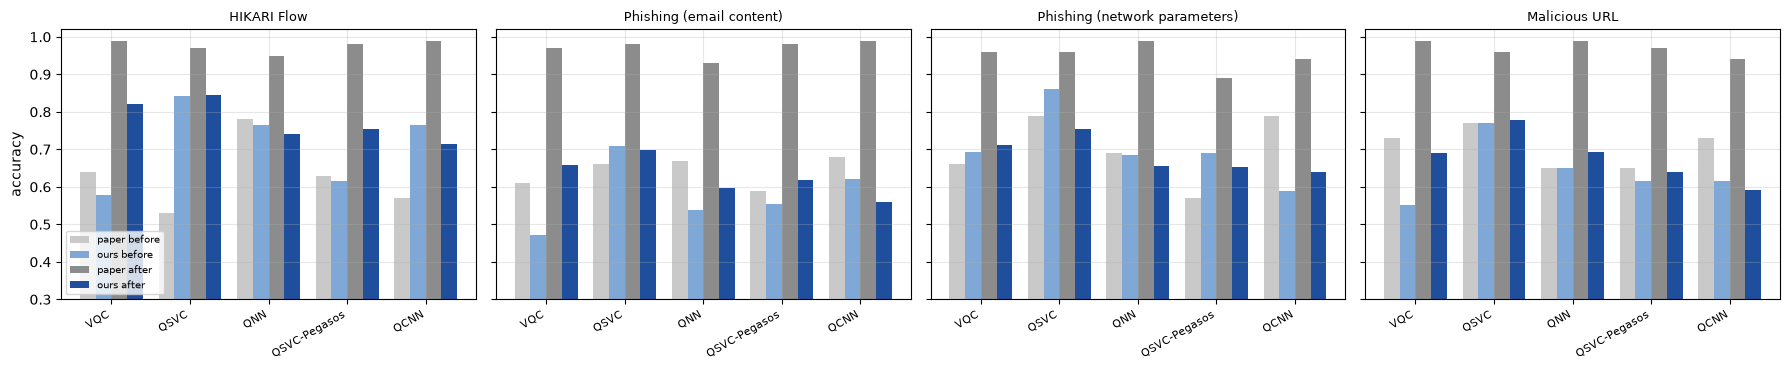

In [16]:
PAPER_T2 = {   # task -> model -> (before, after), paper Table 2
 "HIKARI Flow":                   {"VQC": (0.64, 0.99), "QSVC": (0.53, 0.97), "QNN": (0.78, 0.95), "QSVC-Pegasos": (0.63, 0.98), "QCNN": (0.57, 0.99)},
 "Phishing (email content)":      {"VQC": (0.61, 0.97), "QSVC": (0.66, 0.98), "QNN": (0.67, 0.93), "QSVC-Pegasos": (0.59, 0.98), "QCNN": (0.68, 0.99)},
 "Phishing (network parameters)": {"VQC": (0.66, 0.96), "QSVC": (0.79, 0.96), "QNN": (0.69, 0.99), "QSVC-Pegasos": (0.57, 0.89), "QCNN": (0.79, 0.94)},
 "Malicious URL":                 {"VQC": (0.73, 0.99), "QSVC": (0.77, 0.96), "QNN": (0.65, 0.99), "QSVC-Pegasos": (0.65, 0.97), "QCNN": (0.73, 0.94)},
}
QM = ["VQC", "QSVC", "QNN", "QSVC-Pegasos", "QCNN"]
mean = R.groupby(["task", "model", "stage"])[["acc", "f1"]].mean(); std = R.groupby(["task", "model", "stage"])[["acc", "f1"]].std().fillna(0)
def verdict(ours, paper, tol=0.02): return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")
rows = []
for task in TASKS:
    for m in QM:
        pb, pa = PAPER_T2[task][m]; ob, oa = mean.loc[(task, m, "before"), "acc"], mean.loc[(task, m, "after"), "acc"]
        rows.append(dict(task=task, model=m, paper_before=pb, ours_before=round(ob, 3), verdict_before=verdict(ob, pb), paper_after=pa, ours_after=round(oa, 3),
                         ours_after_std=round(std.loc[(task, m, "after"), "acc"], 3), ours_after_F1=round(mean.loc[(task, m, "after"), "f1"], 3), verdict_after=verdict(oa, pa)))
T2 = pd.DataFrame(rows); display(T2)
print("verdict counts, 'before' column:", {k: int(v) for k, v in T2.verdict_before.value_counts().items()}, "| 'after' column:", {k: int(v) for k, v in T2.verdict_after.value_counts().items()})

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True); w = 0.2
for a, task in zip(ax, TASKS):
    t = T2[T2.task == task]; x = np.arange(len(QM))
    a.bar(x - 1.5 * w, t.paper_before, w, label="paper before", color="#c9c9c9"); a.bar(x - 0.5 * w, t.ours_before, w, label="ours before", color="#7fa8d6")
    a.bar(x + 0.5 * w, t.paper_after, w, label="paper after", color="#8c8c8c"); a.bar(x + 1.5 * w, t.ours_after, w, label="ours after", color="#1f4e9c")
    a.set_xticks(x); a.set_xticklabels(QM, rotation=30, ha="right", fontsize=8); a.set_title(task, fontsize=9); a.set_ylim(0.3, 1.02)
ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

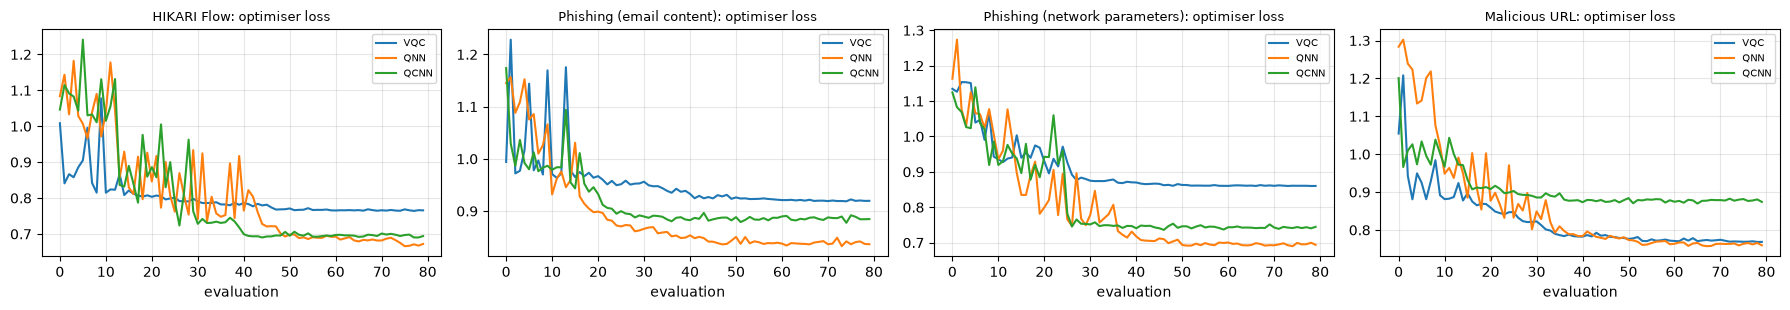

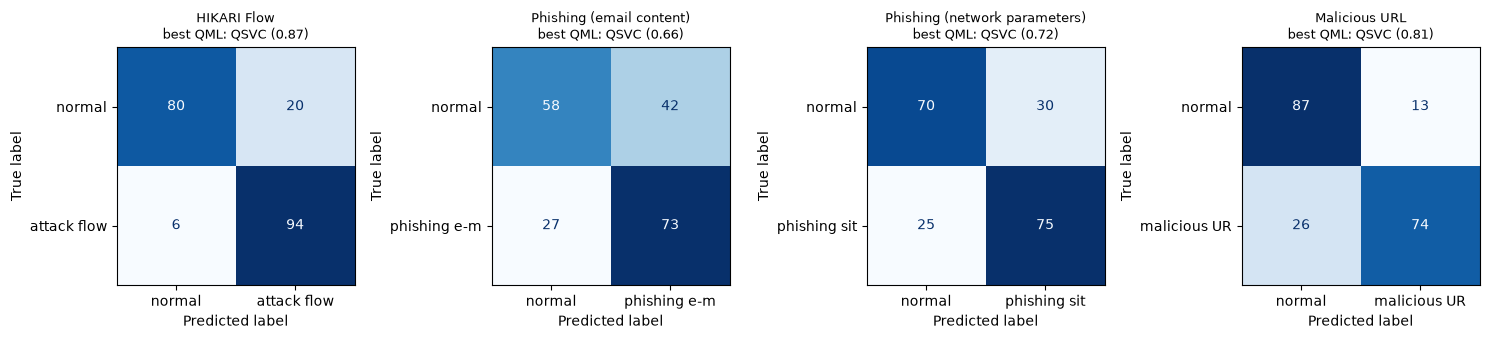

In [17]:
# Training curves of the 'after' variational models (loss reported by the optimiser callback) and confusion matrices of the best QML model per task
fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
for a, task in zip(ax, TASKS):
    for m in ["VQC", "QNN", "QCNN"]:
        l = LOSS[(task, m, "after", SEEDS[0])]; a.plot(l, label=m)
    a.set_title(f"{task}: optimiser loss", fontsize=9); a.set_xlabel("evaluation"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, task in zip(ax, TASKS):
    r = R[(R.task == task) & (R.stage == "after") & (R.seed == SEEDS[0])].sort_values("acc", ascending=False).iloc[0]
    ConfusionMatrixDisplay(np.array([[r.tn, r.fp], [r.fn, r.tp]]), display_labels=["normal", DATA[task]["pos"][:12]]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{task}\nbest QML: {r.model} ({r.acc:.2f})", fontsize=9); a.grid(False)
plt.tight_layout(); plt.show()

## 8. Side-by-side comparison with the paper: one verdict per claim

Verdicts: **reproduced** (within 0.02 of the paper's value, or the qualitative statement holds here), **not reached** / **exceeded** (outside the tolerance, with the gap),
**cannot be checked** (no data, no number, or an experiment that needs hardware or a library not used here).

In [18]:
def A(task, model, stage="after"): return float(mean.loc[(task, model, stage), "acc"])
def F(task, model, stage="after"): return float(mean.loc[(task, model, stage), "f1"])
ph_e, ph_n, hk, ur = "Phishing (email content)", "Phishing (network parameters)", "HIKARI Flow", "Malicious URL"
BASE = ["Decision tree", "Naive Bayes", "Random forest", "Extra trees", "Gradient boosting", "XGBoost", "MLP", "SVC (RBF)"]   # the eight models trained on the engineered features
cl_best = {t: CLASSICAL[t]["acc"].max() for t in TASKS}                        # includes the TF-IDF text models for the e-mail task
cl_best_name = {t: CLASSICAL[t]["acc"].idxmax() for t in TASKS}
base_best = {t: CLASSICAL[t].loc[BASE, "acc"].max() for t in TASKS}
base_best_name = {t: CLASSICAL[t].loc[BASE, "acc"].idxmax() for t in TASKS}
TREES = ["Decision tree", "Random forest", "Extra trees", "Gradient boosting", "XGBoost"]
tree_best = {t: CLASSICAL[t].loc[TREES, "acc"].max() for t in TASKS}
SHORT = {"HIKARI Flow": "HIKARI", "Phishing (email content)": "phish-email", "Phishing (network parameters)": "phish-network", "Malicious URL": "URL"}
q_best = {t: max(A(t, m) for m in QM) for t in TASKS}
q_best_name = {t: max(QM, key=lambda m: A(t, m)) for t in TASKS}
like = lambda t: R[(R.task == t) & (R.stage == "classical")].groupby("model")["acc"].mean()
beats_like = {t: q_best[t] > like(t).max() + 1e-9 for t in TASKS}
imp = np.mean([A(t, m) - A(t, m, "before") for t in TASKS for m in QM])
n_up = int(sum(A(t, m) > A(t, m, "before") for t in TASKS for m in QM))
claims = []
def claim(cid, text, paper, ours, verdict_): claims.append(dict(claim=cid, statement=text, paper=paper, notebook=ours, verdict=verdict_))

claim("C1", "VQC accuracy on HIKARI traffic patterns", "95.12 %", f"{A(hk, 'VQC'):.3f} (after) / {A(hk, 'VQC', 'before'):.3f} (before), 4 qubits, {N_TRAIN_Q} training flows", verdict(A(hk, "VQC"), 0.9512))
claim("C2", "QSVC accuracy for phishing detection", "97.75 % (98.75 % on e-mail content)", f"e-mail {A(ph_e, 'QSVC'):.3f}, network parameters {A(ph_n, 'QSVC'):.3f}, mean {np.mean([A(ph_e, 'QSVC'), A(ph_n, 'QSVC')]):.3f}",
      verdict(np.mean([A(ph_e, "QSVC"), A(ph_n, "QSVC")]), 0.9775))
claim("C3", "QNN F1 score on malicious URLs", "95.62 %", f"{F(ur, 'QNN'):.3f}", verdict(F(ur, "QNN"), 0.9562))
claim("C4", "Table 2: scores after optimisation (20 cells)", "0.89-0.99", f"{T2.verdict_after.eq('reproduced').sum()} reproduced, {T2.verdict_after.eq('not reached').sum()} not reached, {T2.verdict_after.eq('exceeded').sum()} exceeded; mean {T2.ours_after.mean():.3f}",
      "reproduced" if T2.verdict_after.eq("reproduced").mean() >= 0.8 else "not reached (most cells)")
claim("C5", "Table 2: scores before optimisation (20 cells)", "0.53-0.79", f"{T2.verdict_before.eq('reproduced').sum()} reproduced, {T2.verdict_before.eq('not reached').sum()} not reached, {T2.verdict_before.eq('exceeded').sum()} exceeded; mean {T2.ours_before.mean():.3f}",
      "reproduced" if T2.verdict_before.eq("reproduced").mean() >= 0.8 else "partly reproduced")
claim("C6", "Optimisation raises every model's score", "all 20 cells rise", f"{n_up} of 20 cells rise; mean gain {imp:+.3f}", "reproduced" if n_up >= 18 else ("partly reproduced" if n_up >= 12 else "not reached"))
claim("C7", "QML models outperform RF / GB / NN on every task", "QML > classical in all tasks",
      "; ".join(f"{SHORT[t]}: best QML {q_best_name[t]} {q_best[t]:.3f} vs classical (all features) {cl_best_name[t]} {cl_best[t]:.3f}" for t in TASKS) +
      " | same 4 angles: " + ", ".join(f"{SHORT[t]} {'QML above' if beats_like[t] else 'classical >= QML'}" for t in TASKS),
      "reproduced" if all(q_best[t] > cl_best[t] for t in TASKS) else "not reached")
claim("C8", "Noise mitigation gives about 20 % better accuracy", "+20 %", "simulation here is noiseless; no mitigation implemented", "cannot be checked")
b = BB84
claim("C9", "BB84 without eavesdropper: 100 % key match (Fig. 4)", "100 %", f"key match {b.loc['no eavesdropper', 'key_match']:.3f}, QBER {b.loc['no eavesdropper', 'QBER']:.3f}, {int(b.loc['no eavesdropper', 'sifted_key_bits'])} sifted bits",
      "reproduced" if b.loc["no eavesdropper", "key_match"] == 1 else "not reached")
claim("C10", "BB84 with eavesdropper: disturbance detected, session aborted (Figs. 5-6)", "detected", f"QBER {b.loc['eavesdropper', 'QBER']:.3f} (theory 0.25) > {QBER_THRESHOLD} -> abort = {b.loc['eavesdropper', 'abort']}",
      "reproduced" if b.loc["eavesdropper", "abort"] else "not reached")
claim("C11", "BB84 under realistic noise stays usable", "secure in noisy conditions", f"QBER {b.loc['noisy channel', 'QBER']:.3f} -> abort = {b.loc['noisy channel', 'abort']}", "reproduced" if not b.loc["noisy channel", "abort"] else "not reached")
claim("C12", "Cirq implementation of BB84", "Qiskit and Cirq", "only Qiskit/Aer is run here", "cannot be checked")
claim("C13", "Classical ensembles are best, naive Bayes worst (Figs. 8-11)", "qualitative",
      "; ".join(f"{SHORT[t]}: best {base_best_name[t]} {base_best[t]:.3f}, best tree/ensemble {tree_best[t]:.3f}, NB {CLASSICAL[t].loc['Naive Bayes', 'acc']:.3f}" for t in TASKS),
      "reproduced" if all(tree_best[t] >= base_best[t] - 0.01 and CLASSICAL[t].loc["Naive Bayes", "acc"] < base_best[t] - 0.02 for t in TASKS) else "partly reproduced")
xg = max(CLASSICAL[ph_e].loc["XGBoost", "acc"], CLASSICAL[ph_e].loc["XGBoost (TF-IDF words)", "acc"])
claim("C14", "XGBoost / CatBoost above 98 % on phishing e-mail content", "> 98 %", f"XGBoost on the 12 engineered features {CLASSICAL[ph_e].loc['XGBoost', 'acc']:.3f}; on TF-IDF words {CLASSICAL[ph_e].loc['XGBoost (TF-IDF words)', 'acc']:.3f}",
      "reproduced" if xg > 0.98 else ("not reached (" + f"{xg - 0.98:+.3f}" + ")"))
claim("C15", "Post-quantum cryptography integrated (Kyber / Dilithium)", "named only", "no experiment, number or timing in the paper", "cannot be checked")
CL = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 220); display(CL)

,claim,statement,paper,notebook,verdict
0,C1,VQC accuracy on HIKARI traffic patterns,95.12 %,"0.823 (after) / 0.577 (before), 4 qubits, 80 training flows",not reached
1,C2,QSVC accuracy for phishing detection,97.75 % (98.75 % on e-mail content),"e-mail 0.698, network parameters 0.755, mean 0.726",not reached
2,C3,QNN F1 score on malicious URLs,95.62 %,0.691,not reached
3,C4,Table 2: scores after optimisation (20 cells),0.89-0.99,"0 reproduced, 20 not reached, 0 exceeded; mean 0.691",not reached (most cells)
4,C5,Table 2: scores before optimisation (20 cells),0.53-0.79,"5 reproduced, 9 not reached, 6 exceeded; mean 0.659",partly reproduced
5,C6,Optimisation raises every model's score,all 20 cells rise,12 of 20 cells rise; mean gain +0.032,partly reproduced
6,C7,QML models outperform RF / GB / NN on every task,QML > classical in all tasks,HIKARI: best QML QSVC 0.845 vs classical (all features) MLP 0.958; phish-email: best QML QSVC 0.698 vs classical (all features) Logistic regression (TF-IDF words) 0.959; phish-network: best QML QSVC 0.755 vs classica...,not reached
7,C8,Noise mitigation gives about 20 % better accuracy,+20 %,simulation here is noiseless; no mitigation implemented,cannot be checked
8,C9,BB84 without eavesdropper: 100 % key match (Fig. 4),100 %,"key match 1.000, QBER 0.000, 2021 sifted bits",reproduced
9,C10,"BB84 with eavesdropper: disturbance detected, session aborted (Figs. 5-6)",detected,QBER 0.258 (theory 0.25) > 0.11 -> abort = True,reproduced


In [19]:
print("Per-seed variation of the 'after' accuracy (std over seeds; one seed gives 0):")
display(std.xs("after", level="stage")["acc"].unstack().round(3))
print("\nLike-for-like classical baselines on the same four angles (mean accuracy):")
display(R[R.stage == "classical"].groupby(["task", "model"])["acc"].mean().unstack().round(3))
print("\nWall-clock seconds per fit (mean):")
display(R[R.stage != "classical"].groupby(["model", "stage"])["seconds"].mean().unstack().round(1))

Per-seed variation of the 'after' accuracy (std over seeds; one seed gives 0):


model,QCNN,QNN,QSVC,QSVC-Pegasos,VQC
task,,,,,
HIKARI Flow,0.127,0.021,0.035,0.028,0.060
Malicious URL,0.067,0.074,0.039,0.170,0.035
Phishing (email content),0.042,0.039,0.060,0.053,0.025
Phishing (network parameters),0.028,0.064,0.042,0.103,0.074



Like-for-like classical baselines on the same four angles (mean accuracy):


model,GB (4 angles),RF (4 angles),SVC-RBF (4 angles)
task,,,
HIKARI Flow,0.825,0.830,0.825
Malicious URL,0.762,0.770,0.772
Phishing (email content),0.685,0.695,0.720
Phishing (network parameters),0.855,0.867,0.878



Wall-clock seconds per fit (mean):


stage,after,before
model,,
QCNN,158.7,31.1
QNN,113.6,8.2
QSVC,3.4,1.4
QSVC-Pegasos,2.4,0.7
VQC,229.4,25.1


## 9. Reading the paper critically

* **The data are private and unnamed.** "HIKARI Flow", "Phishing" and "Malicious URL" are not given a file, size, split or version; the data are "available on reasonable request". All four data sets here are public substitutes
  of the same kind, so any difference from the paper may be due to the data rather than to the models.
* **What is "the score"?** Table 2 lists a number between 0.53 and 0.99 per model and task without saying whether it is accuracy, F1 or something else, whether it is a test or training score, how many samples were used
  and how many repeats. The text quotes accuracies and F1 scores of the same models that do not match the table (for example QNN is 0.95 on HIKARI in the table, but the text calls 95.12 % the VQC's traffic accuracy; the table has VQC at 0.99).
* **Inconsistent headlines.** The abstract says "maximum phishing detection accuracy of 97.75 % by QSVC", Section 4.6 calls 97.75 % the QSVC's "average output accuracy", Section 4.7 gives 98.75 % on e-mail content, while Table 2 has QSVC at 0.98
  and 0.96 on the two phishing tasks. Section 4.2 announces four data sets and lists three.
* **Classical models are not beaten in their own numbers.** The text says decision trees and gradient boosting are "near perfect" on HIKARI and CatBoost/XGBoost exceed 98 % on e-mails. A QML model with a handful of qubits
  scoring 0.97 to 0.99 on the same tasks cannot "outperform" them by a meaningful margin, and the paper shows no like-for-like numbers, confidence intervals or statistical test. The bar charts (Figures 8-11) have no printed values.
* **Very high scores on very small quantum models are not what we find.** The paper does not say how many qubits or samples were used. With 4 qubits and 80 training rows per task (two seeds), the five QML models reach a mean
  accuracy of **0.69 after optimisation** (Table 2 of the paper: 0.89 to 0.99 in every cell; best single cell here: 0.85, QSVC on HIKARI), and none of the 20 cells is within 0.02 of the paper. The classical models trained on the full engineered feature
  sets reach 0.96 (HIKARI, MLP), 0.96 (phishing network parameters, random forest), 0.86 (malicious URL, extra trees) and 0.84 / 0.96 (e-mail: engineered features / TF-IDF words). Random forest and RBF-SVC on the **same four angles** as the quantum
  models reach 0.83 (HIKARI), 0.88 (phishing network), 0.77 (URL) and 0.72 (e-mail), so the best QML model is level with them on HIKARI, URL and e-mail (differences of about 0.02 or less) and 0.12 below them on the phishing network parameters.
  More qubits or samples may change this, but the paper gives no number that would let a reader test it.
* **"Before" and "after" are not defined, and generic tuning does not produce the paper's jump.** The paper's "before" scores (0.53 to 0.79) are close to chance for a two-class problem. Our "before" (library defaults, 10 iterations) has a mean accuracy of 0.66
  and our "after" 0.69; only 12 of the 20 cells rise. For the QSVC, choosing the kernel bandwidth and `C` by cross-validation does not help on average (HIKARI 0.84 to 0.85, e-mail 0.71 to 0.70, phishing network 0.86 to 0.76, URL 0.77 to 0.78): with this little data, the
  default kernel was already near the best choice. Whatever produced the paper's +0.3 to +0.4 must be something other than ordinary hyper-parameter tuning.
* **Noise mitigation is claimed, not shown.** "Noise mitigation techniques produced 20 % better accuracy" has no ablation, no noise model and no backend in the paper; the experiments appear to be noiseless simulations, and the NISQ
  claims (and the Cirq runs) cannot be verified.
* **The BB84 and ML parts are not connected.** The key exchange protects nothing in the detectors; "the simulated keys became part of the QML system" is not made operational. The post-quantum-cryptography part has no experiment.
  The BB84 results (100 % match without Eve, detection with Eve) are textbook facts that any simulator reproduces; the interesting numbers (QBER, key length, threshold D) are not reported.
* **Optimiser statements conflict.** COBYLA is called suitable for QSVC, but QSVC is a convex kernel SVM that needs no optimiser; Pegasos uses stochastic sub-gradient steps, not COBYLA or Adam.
* **Net verdict of this notebook.** Reproduced: the BB84 behaviour (100 % key match without an eavesdropper, QBER about 0.26 with an intercept-resend eavesdropper against the theoretical 0.25, QBER 0.03 under 2 % gate noise and 1 % read-out error) and the qualitative classical-model
  statements (tree ensembles are at or next to the top, naive Bayes is worst). Not reached: every headline QML number (VQC 95.12 %, QSVC 97.75 %, QNN F1 95.62 %) and all 20 "after" cells of Table 2, with the caveat that the paper's data, qubit count and sample sizes are unknown and
  that our test sets have 200 rows (one error is 0.005). Cannot be checked: the noise-mitigation gain, the Cirq runs and the post-quantum-cryptography part. The notebook therefore reports the paper as **partially reproduced**.


## 10. Exercises

1. **Qubits.** Set `N_QUBITS = 8` (the QCNN needs a different ansatz then: use three conv/pool stages) and rerun a single task. Does the gap to the classical baselines on the same angles shrink?
2. **Feature map.** Replace `zz_feature_map` by `pauli_feature_map(N_QUBITS, paulis=["Z", "YY"])` in the "after" stage. How do the kernel validation accuracy and the test accuracy change?
3. **Noise.** Run the QNN of one task through `AerSimulator(noise_model=noise_model())` using `qiskit_aer.primitives.EstimatorV2`, then add measurement-error mitigation. Is the paper's "20 % gain" plausible for your numbers?
4. **QBER.** In `run_bb84` let Eve intercept only a fraction `f` of the qubits. Plot the QBER against `f` and find the largest `f` that stays under the 11 % threshold.
5. **Statistics.** Increase `SEEDS` to five and `N_TEST_Q` to 400. Compute a 95 % confidence interval for each cell of Table 2. Which of the paper's cells does your interval exclude?